# LAIA — Exploratory Data Analysis

BTS domestic flights, 2022–2023.

## 1.1 Dataset and Coverage

Data: BTS TranStats, 2022–2023; monthly Parquet files. Verify counts and field availability below.

## 1.2 Load Data

In [1]:
import os
from pathlib import Path
from datetime import date
import calendar

import numpy as np
import matplotlib.pyplot as plt
import polars as pl

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR_ENV = os.getenv("LAIA_DATA_DIR")
if DATA_DIR_ENV:
    DATA_DIR = Path(DATA_DIR_ENV).expanduser().resolve()
else:
    DATA_DIR = next(
        (p / "data" / "raw" for p in (Path.cwd(), *Path.cwd().parents)
         if (p / "data" / "raw").is_dir()),
        None,
    )

if DATA_DIR is None or not DATA_DIR.is_dir() or not list(DATA_DIR.glob("*.parquet")):
    raise FileNotFoundError(
        "Parquet files not found. Open this notebook in the LAIA repository "
        "(containing data/raw/*.parquet) or set LAIA_DATA_DIR."
    )

print("Data directory:", DATA_DIR)
print("Monthly parquet files:", len(list(DATA_DIR.glob("*.parquet"))))
df = pl.scan_parquet(str(DATA_DIR / "*.parquet"))
print("Schema columns:", len(df.collect_schema()))
print("Polars:", pl.__version__)


Data directory: c:\laia\laia_project_group_12\data\raw
Monthly parquet files: 24
Schema columns: 43
Polars: 2.1.0


In [2]:
overview = df.select(
    pl.len().alias("flights"),
    pl.col("FL_DATE").min().alias("first_date"),
    pl.col("FL_DATE").max().alias("last_date"),
    pl.col("FL_DATE").n_unique().alias("unique_days"),
    pl.col("YEAR").n_unique().alias("years"),
    pl.struct(["YEAR", "MONTH"]).n_unique().alias("year_month_periods"),
    pl.col("ORIGIN_AIRPORT_ID").n_unique().alias("origin_airports"),
    pl.col("DEST_AIRPORT_ID").n_unique().alias("destination_airports"),
    pl.struct(["ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID"]).n_unique().alias("directed_routes"),
    pl.col("OP_UNIQUE_CARRIER").n_unique().alias("airlines"),
    pl.col("TAIL_NUM").drop_nulls().n_unique().alias("aircraft_known"),
).collect(engine="streaming")

display(overview)
print("Number of attributes:", len(df.collect_schema()))


flights,first_date,last_date,unique_days,years,year_month_periods,origin_airports,destination_airports,directed_routes,airlines,aircraft_known
u32,datetime[ns],datetime[ns],u32,u32,u32,u32,u32,u32,u32,u32
13577024,2022-01-01 00:00:00,2023-12-31 00:00:00,730,2,24,372,373,7163,17,6360


Number of attributes: 43


## 1.3 Data Dictionary

### Temporal Attributes

| Attribute | Data Type | Description |
|---|---|---|
| `YEAR` | Int64 | Year of the flight. |
| `QUARTER` | Int64 | Quarter of the year (1–4). |
| `MONTH` | Int64 | Month of the year (1–12). |
| `DAY_OF_MONTH` | Int64 | Day of the month (1–31). |
| `DAY_OF_WEEK` | Int64 | Day of the week (1 = Monday, 7 = Sunday). |
| `FL_DATE` | datetime64 | Flight date. Derived during ingestion from year, month and day. |

### Airline and Aircraft Attributes

| Attribute | Data Type | Description |
|---|---|---|
| `OP_UNIQUE_CARRIER` | string | Unique code identifying the operating airline. |
| `OP_CARRIER_AIRLINE_ID` | Int64 | DOT identification number of the operating airline. |
| `TAIL_NUM` | string | Aircraft registration number identifying the aircraft. |
| `OP_CARRIER_FL_NUM` | Int64 | Flight number assigned by the operating airline. |

### Origin Airport Attributes

| Attribute | Data Type | Description |
|---|---|---|
| `ORIGIN_AIRPORT_ID` | Int64 | Unique DOT identifier of the origin airport. |
| `ORIGIN_AIRPORT_SEQ_ID` | Int64 | Airport sequence identifier associated with a particular airport record. |
| `ORIGIN_CITY_MARKET_ID` | Int64 | Identifier of the origin airport's city market. |
| `ORIGIN` | string | Origin airport code. |
| `ORIGIN_CITY_NAME` | string | Name of the origin city. |
| `ORIGIN_STATE_ABR` | string | Abbreviation of the origin state. |
| `ORIGIN_STATE_NM` | string | Full name of the origin state. |
| `ORIGIN_WAC` | Int64 | World Area Code associated with the origin airport. |

### Destination Airport Attributes

| Attribute | Data Type | Description |
|---|---|---|
| `DEST_AIRPORT_ID` | Int64 | Unique DOT identifier of the destination airport. |
| `DEST_AIRPORT_SEQ_ID` | Int64 | Airport sequence identifier associated with a particular airport record. |
| `DEST_CITY_MARKET_ID` | Int64 | Identifier of the destination airport's city market. |
| `DEST` | string | Destination airport code. |
| `DEST_CITY_NAME` | string | Name of the destination city. |
| `DEST_STATE_ABR` | string | Abbreviation of the destination state. |
| `DEST_STATE_NM` | string | Full name of the destination state. |
| `DEST_WAC` | Int64 | World Area Code associated with the destination airport. |

### Scheduled Flight Attributes

| Attribute | Data Type | Description | Unit |
|---|---|---|---|
| `CRS_DEP_TIME` | Int64 | Scheduled departure time (local time). | HHMM |
| `CRS_ARR_TIME` | Int64 | Scheduled arrival time (local time). | HHMM |
| `CRS_ELAPSED_TIME` | Float64 | Scheduled flight duration. | Minutes |
| `DISTANCE` | Float64 | Distance between origin and destination airports. | Miles |
| `DISTANCE_GROUP` | Int64 | Distance interval classification. | Category |

### Actual Flight Operation Attributes

| Attribute | Data Type | Description | Unit |
|---|---|---|---|
| `DEP_TIME` | Int64 | Actual departure time (local time). | HHMM |
| `DEP_DELAY` | Float64 | Difference between actual and scheduled departure time. Negative values indicate early departures. | Minutes |
| `TAXI_OUT` | Float64 | Time elapsed between leaving the departure gate and takeoff. | Minutes |
| `TAXI_IN` | Float64 | Time elapsed between landing and arrival at the destination gate. | Minutes |
| `ARR_TIME` | Int64 | Actual arrival time (local time). | HHMM |
| `ARR_DELAY` | Float64 | Difference between actual and scheduled arrival time. Negative values indicate early arrivals. | Minutes |

### Flight Status Attributes

| Attribute | Data Type | Description |
|---|---|---|
| `CANCELLED` | Float64 | Binary indicator identifying whether the flight was cancelled (1 = cancelled, 0 = not cancelled). |
| `DIVERTED` | Float64 | Binary indicator identifying whether the flight was diverted (1 = diverted, 0 = not diverted). |

### Additional Operational Attributes

| Attribute | Data Type | Description | Unit |
|---|---|---|---|
| `FLIGHTS` | Int64 | Number of flights represented by the record, typically 1. | Count |
| `FIRST_DEP_TIME` | Int64 | Initial gate departure time when a flight subsequently returns to the gate. | HHMM |
| `TOTAL_ADD_GTIME` | Float64 | Total additional ground time associated with gate returns. | Minutes |
| `LONGEST_ADD_GTIME` | Float64 | Longest individual additional ground-time interval associated with a gate return. | Minutes |

### 1.3.1 Schema Validation

Check column presence, data-type families and plausible ranges. Airport routes are directed; flight numbers alone are not unique identifiers. Missing operational measurements may be valid for cancelled or diverted flights.

In [3]:
EXPECTED_COLUMNS = ['YEAR', 'QUARTER', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'FL_DATE', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'TAIL_NUM', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN_CITY_MARKET_ID', 'ORIGIN', 'ORIGIN_CITY_NAME', 'ORIGIN_STATE_ABR', 'ORIGIN_STATE_NM', 'ORIGIN_WAC', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST_CITY_MARKET_ID', 'DEST', 'DEST_CITY_NAME', 'DEST_STATE_ABR', 'DEST_STATE_NM', 'DEST_WAC', 'CRS_DEP_TIME', 'CRS_ARR_TIME', 'CRS_ELAPSED_TIME', 'DISTANCE', 'DISTANCE_GROUP', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'TAXI_IN', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'DIVERTED', 'FLIGHTS', 'FIRST_DEP_TIME', 'TOTAL_ADD_GTIME', 'LONGEST_ADD_GTIME']
actual_schema = df.collect_schema()
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(actual_schema))
extra_columns = sorted(set(actual_schema) - set(EXPECTED_COLUMNS))

print("Missing expected columns:", missing_columns)
print("Extra columns:", extra_columns)
print("Column count:", len(actual_schema))

# Do not cast columns or drop records during EDA.
for name, dtype in actual_schema.items():
    print(f"{name:<25} {dtype}")


Missing expected columns: []
Extra columns: []
Column count: 43
YEAR                      Int64
QUARTER                   Int64
MONTH                     Int64
DAY_OF_MONTH              Int64
DAY_OF_WEEK               Int64
OP_UNIQUE_CARRIER         String
OP_CARRIER_AIRLINE_ID     Int64
TAIL_NUM                  String
OP_CARRIER_FL_NUM         Int64
ORIGIN_AIRPORT_ID         Int64
ORIGIN_AIRPORT_SEQ_ID     Int64
ORIGIN_CITY_MARKET_ID     Int64
ORIGIN                    String
ORIGIN_CITY_NAME          String
ORIGIN_STATE_ABR          String
ORIGIN_STATE_NM           String
ORIGIN_WAC                Int64
DEST_AIRPORT_ID           Int64
DEST_AIRPORT_SEQ_ID       Int64
DEST_CITY_MARKET_ID       Int64
DEST                      String
DEST_CITY_NAME            String
DEST_STATE_ABR            String
DEST_STATE_NM             String
DEST_WAC                  Int64
CRS_DEP_TIME              Int64
DEP_TIME                  Int64
DEP_DELAY                 Float64
TAXI_OUT                  Fl

In [4]:
# Check broad type families to detect schema changes.
string_columns = ["OP_UNIQUE_CARRIER", "TAIL_NUM", "ORIGIN", "DEST"]
numeric_columns = [
    "YEAR", "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "OP_CARRIER_FL_NUM",
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
    "DEP_DELAY", "ARR_DELAY", "CANCELLED", "DIVERTED",
]

type_findings = []
for col in string_columns:
    if col in actual_schema and actual_schema[col] != pl.String:
        type_findings.append(f"{col}: expected string-like, observed {actual_schema[col]}")
for col in numeric_columns:
    if col in actual_schema and not actual_schema[col].is_numeric():
        type_findings.append(f"{col}: expected numeric, observed {actual_schema[col]}")
if "FL_DATE" in actual_schema and not actual_schema["FL_DATE"].is_temporal():
    type_findings.append(f"FL_DATE: expected temporal, observed {actual_schema['FL_DATE']}")

print("Type-family findings:", type_findings if type_findings else "None")


Type-family findings: None


## 1.4 Temporal Coverage

Compare flight counts over time. Monthly totals are affected by the number of days.

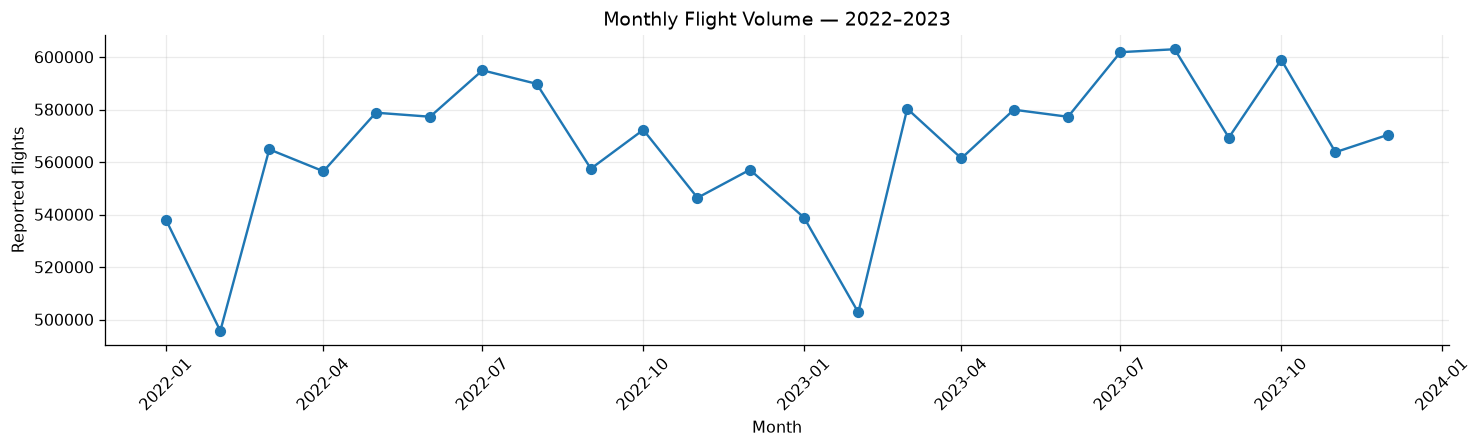

In [5]:
monthly_flights = (
    df.group_by("YEAR", "MONTH")
    .agg(pl.len().alias("flights"))
    .sort("YEAR", "MONTH")
    .collect(engine="streaming")
    .with_columns(pl.date("YEAR", "MONTH", pl.lit(1)).alias("date"))
)

daily_flights = (
    df.group_by("FL_DATE")
    .agg(pl.len().alias("flights"))
    .sort("FL_DATE")
    .collect(engine="streaming")
)

monthly_avg = monthly_flights.with_columns(
    pl.struct(["YEAR", "MONTH"]).map_elements(
        lambda x: calendar.monthrange(int(x["YEAR"]), int(x["MONTH"]))[1],
        return_dtype=pl.Int64,
    ).alias("days_in_month")
).with_columns(
    (pl.col("flights") / pl.col("days_in_month")).alias("avg_daily_flights")
)

plt.figure(figsize=(13, 4))
plt.plot(monthly_flights["date"].to_list(), monthly_flights["flights"].to_list(), marker="o")
plt.title("Monthly Flight Volume — 2022–2023")
plt.ylabel("Reported flights")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()


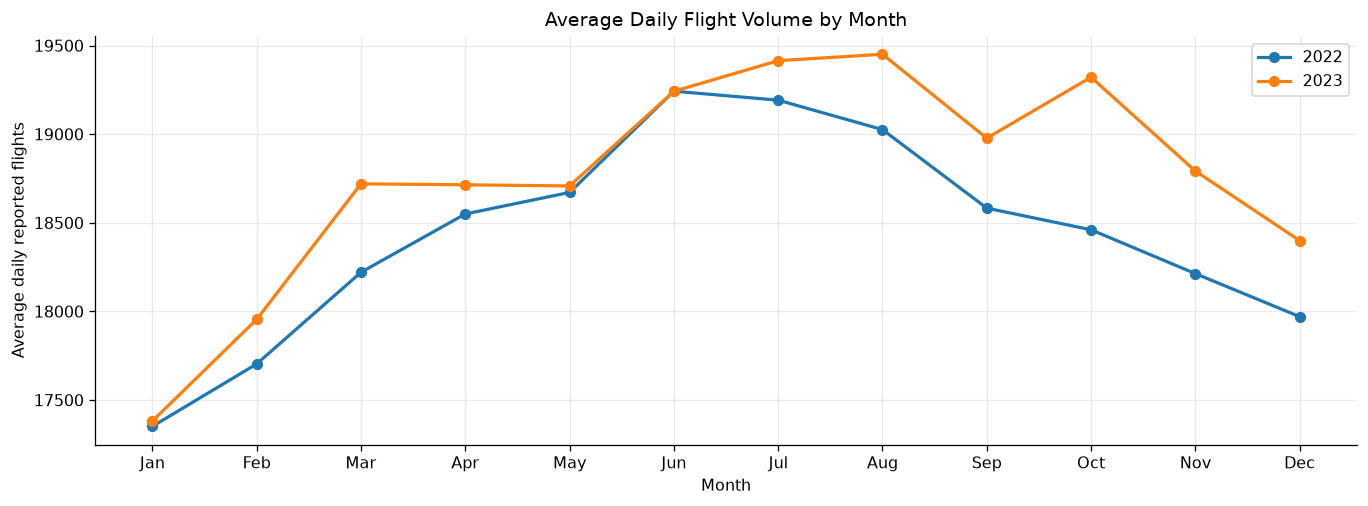

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for year in [2022, 2023]:
    v = monthly_avg.filter(pl.col("YEAR") == year).sort("MONTH")
    ax.plot(v["MONTH"].to_list(), v["avg_daily_flights"].to_list(),
            marker="o", linewidth=2, label=str(year))
ax.set(title="Average Daily Flight Volume by Month", xlabel="Month",
       ylabel="Average daily reported flights")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()


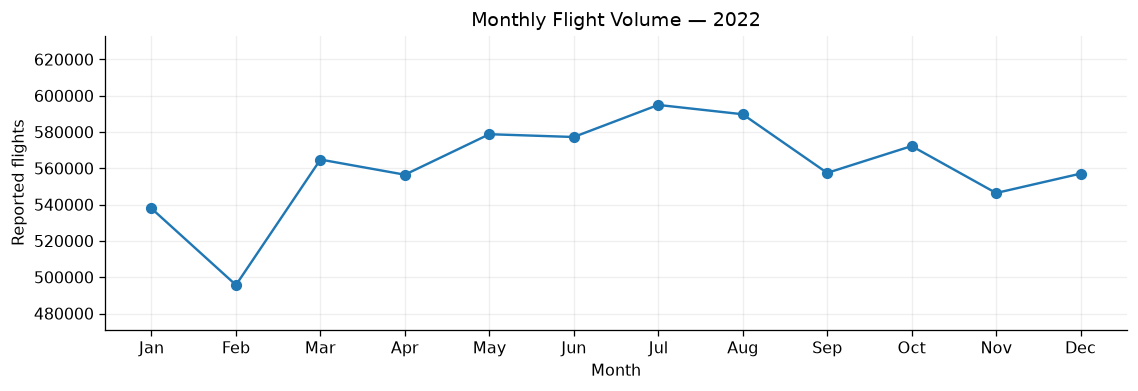

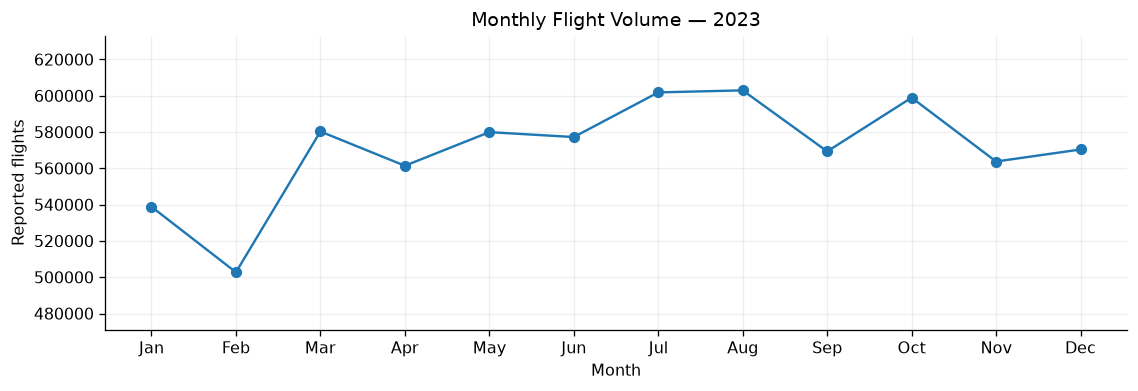

In [7]:
# Use the same vertical scale when comparing years.
monthly_y_min = float(monthly_flights["flights"].min()) * .95
monthly_y_max = float(monthly_flights["flights"].max()) * 1.05
for year in [2022, 2023]:
    v = monthly_flights.filter(pl.col("YEAR") == year).sort("MONTH")
    plt.figure(figsize=(10, 3.5))
    plt.plot(v["MONTH"].to_list(), v["flights"].to_list(), marker="o")
    plt.title(f"Monthly Flight Volume — {year}")
    plt.xticks(range(1,13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    plt.xlabel("Month")
    plt.ylabel("Reported flights")
    plt.ylim(monthly_y_min, monthly_y_max)
    plt.grid(alpha=.2)
    plt.tight_layout()
    plt.show()


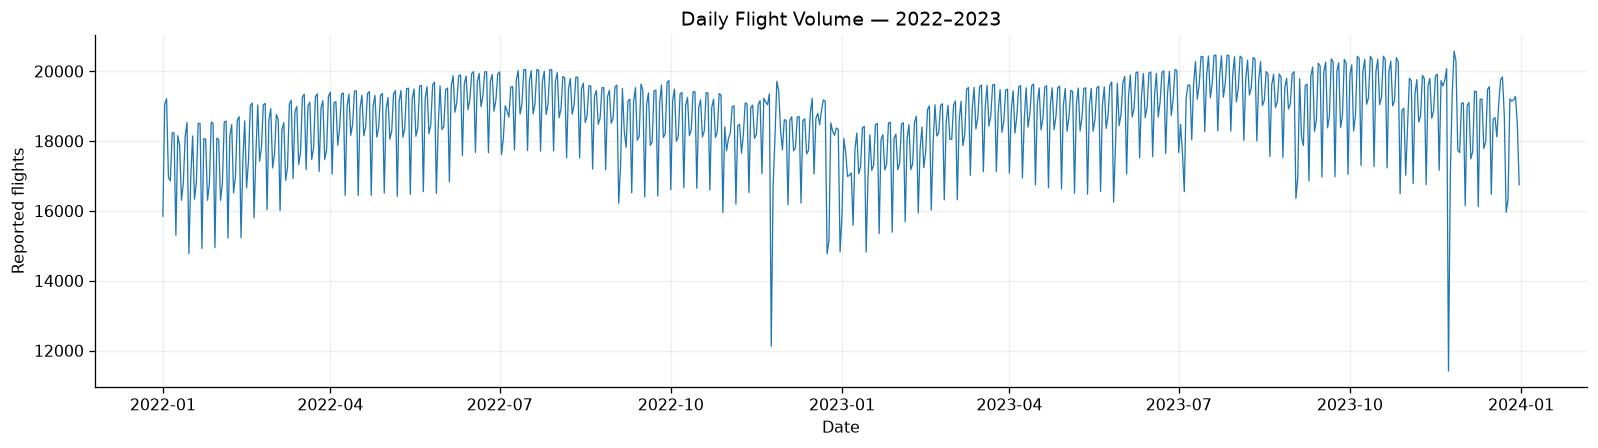

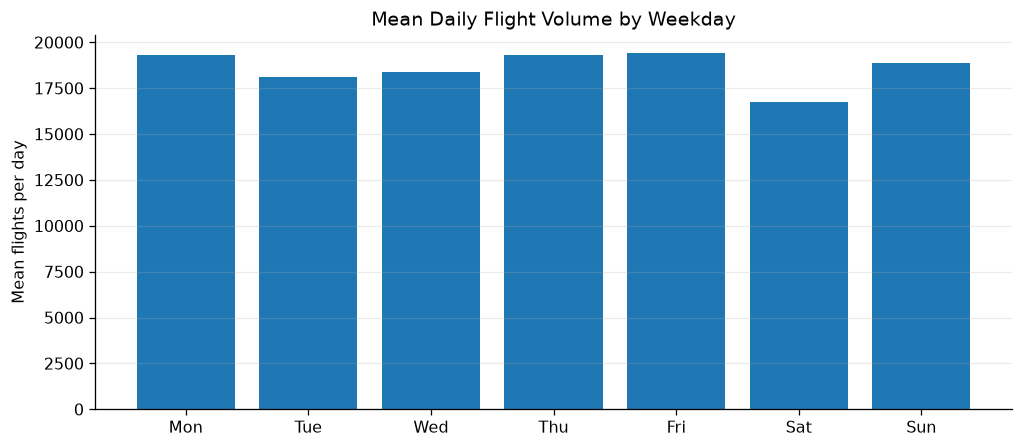

In [8]:
plt.figure(figsize=(14, 4))
plt.plot(daily_flights["FL_DATE"].to_list(), daily_flights["flights"].to_list(), linewidth=.8)
plt.title("Daily Flight Volume — 2022–2023")
plt.ylabel("Reported flights")
plt.xlabel("Date")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

weekday_volume = (
    daily_flights.with_columns(pl.col("FL_DATE").dt.weekday().alias("weekday"))
    .group_by("weekday").agg(pl.col("flights").mean().alias("mean_daily_flights"))
    .sort("weekday")
)
plt.figure(figsize=(9, 4))
plt.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
        weekday_volume["mean_daily_flights"].to_list())
plt.title("Mean Daily Flight Volume by Weekday")
plt.ylabel("Mean flights per day")
plt.grid(axis="y",alpha=.25)
plt.tight_layout()
plt.show()


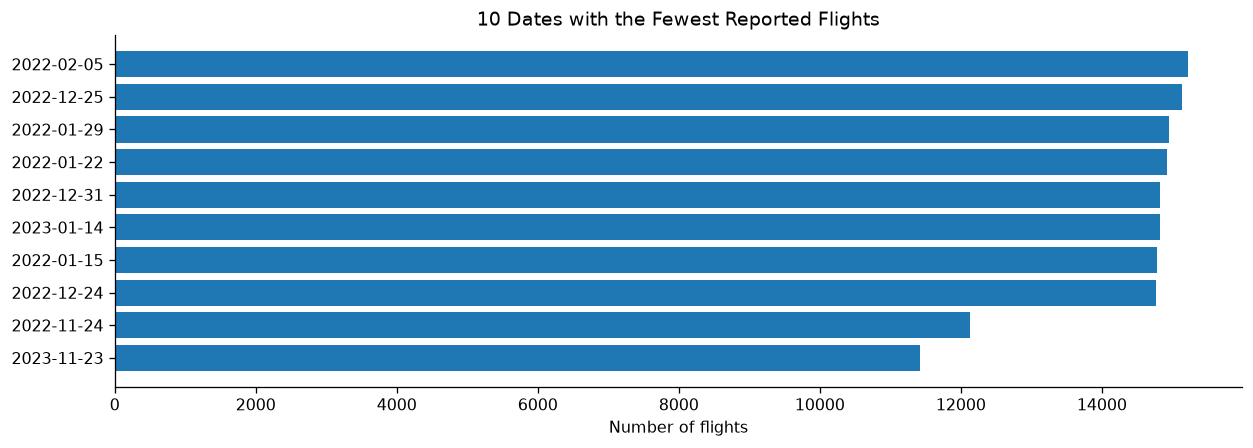

YEAR,flights
i64,u32
2022,6729125
2023,6847899


Distinct dates observed: 730
Year-month periods observed: 24


In [9]:
# Low-volume dates do not by themselves indicate ingestion failures.
lowest_days = daily_flights.sort("flights").head(10).sort("flights")
plt.figure(figsize=(11, 4))
plt.barh([str(d)[:10] for d in lowest_days["FL_DATE"].to_list()], lowest_days["flights"].to_list())
plt.title("10 Dates with the Fewest Reported Flights")
plt.xlabel("Number of flights")
plt.tight_layout()
plt.show()

by_year = monthly_flights.group_by("YEAR").agg(pl.col("flights").sum().alias("flights")).sort("YEAR")
display(by_year)
print("Distinct dates observed:", daily_flights.height)
print("Year-month periods observed:", monthly_flights.height)


## 1.5 Airports

Counts represent scheduled/reported movements, not necessarily completed takeoffs or landings.

In [10]:
origins = set(df.select(pl.col("ORIGIN_AIRPORT_ID").drop_nulls().unique()).collect(engine="streaming").to_series().to_list())
destinations = set(df.select(pl.col("DEST_AIRPORT_ID").drop_nulls().unique()).collect(engine="streaming").to_series().to_list())
print("All airports:", len(origins | destinations))
print("Origins:", len(origins), "Destinations:", len(destinations))
print("Only origins:", sorted(origins - destinations))
print("Only destinations:", sorted(destinations - origins))

outbound = df.group_by("ORIGIN_AIRPORT_ID").agg(
    pl.len().alias("departures"), pl.col("ORIGIN").first().alias("origin_code")
).rename({"ORIGIN_AIRPORT_ID": "airport_id"})
inbound = df.group_by("DEST_AIRPORT_ID").agg(
    pl.len().alias("arrivals"), pl.col("DEST").first().alias("dest_code")
).rename({"DEST_AIRPORT_ID": "airport_id"})

airport_counts = (
    outbound.join(inbound, on="airport_id", how="full", coalesce=True)
    .with_columns(
        pl.coalesce("origin_code", "dest_code").alias("airport"),
        pl.col("departures").fill_null(0), pl.col("arrivals").fill_null(0),
    )
    .with_columns((pl.col("departures") + pl.col("arrivals")).alias("total"))
    .select("airport_id", "airport", "departures", "arrivals", "total")
    .collect(engine="streaming")
)

if int(airport_counts["total"].sum()) != 2 * int(overview["flights"][0]):
    print("Note: movements do not total twice the flights; check missing airport IDs.")


All airports: 373
Origins: 372 Destinations: 373
Only origins: []
Only destinations: [10590]


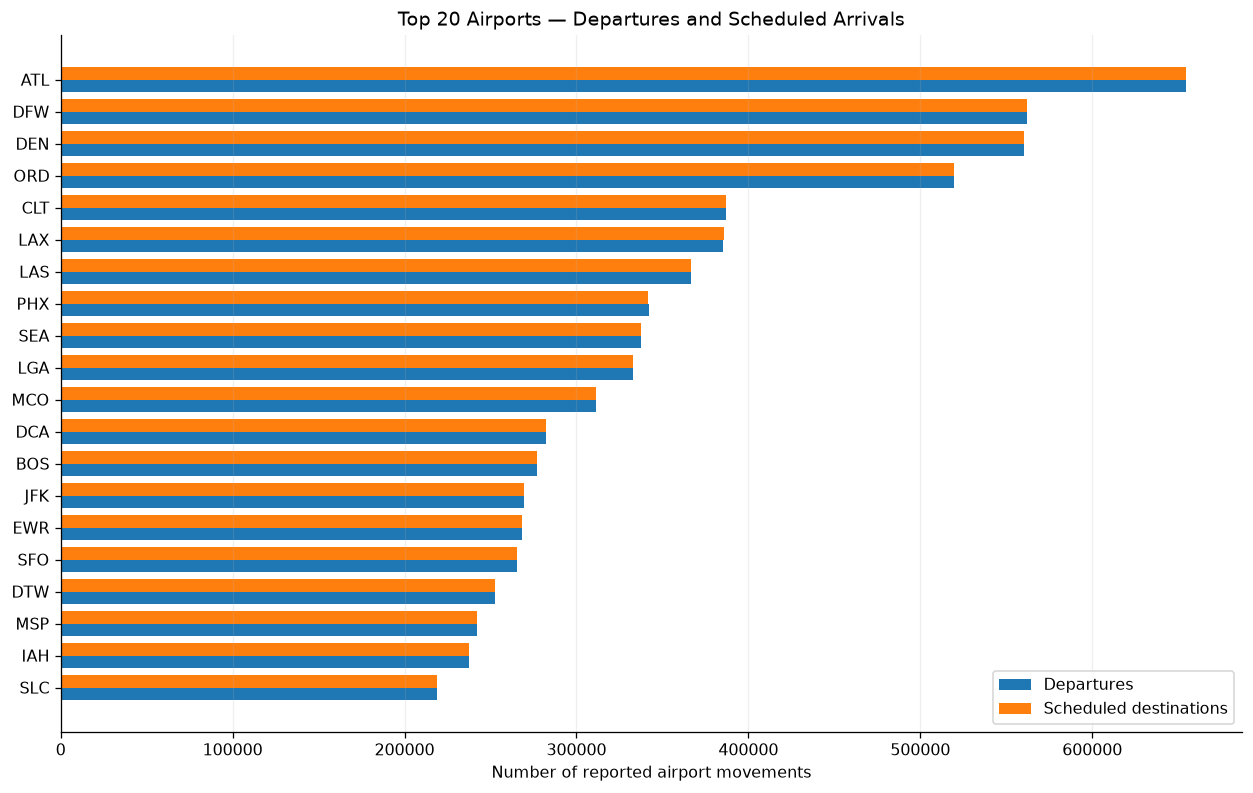

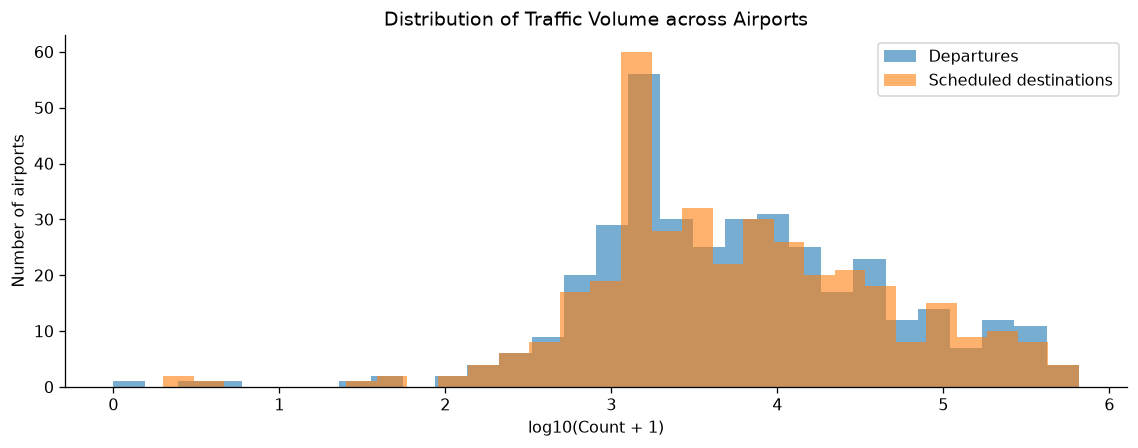

In [11]:
top20_airports = airport_counts.sort("total", descending=True).head(20).sort("total")
y = np.arange(top20_airports.height)
plt.figure(figsize=(11, 7))
plt.barh(y-.2, top20_airports["departures"].to_numpy(), height=.4, label="Departures")
plt.barh(y+.2, top20_airports["arrivals"].to_numpy(), height=.4, label="Scheduled destinations")
plt.yticks(y, top20_airports["airport"].to_list())
plt.xlabel("Number of reported airport movements")
plt.title("Top 20 Airports — Departures and Scheduled Arrivals")
plt.legend()
plt.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(np.log10(airport_counts["departures"].to_numpy()+1), bins=30, alpha=.6, label="Departures")
plt.hist(np.log10(airport_counts["arrivals"].to_numpy()+1), bins=30, alpha=.6, label="Scheduled destinations")
plt.xlabel("log10(Count + 1)")
plt.ylabel("Number of airports")
plt.title("Distribution of Traffic Volume across Airports")
plt.legend()
plt.tight_layout()
plt.show()


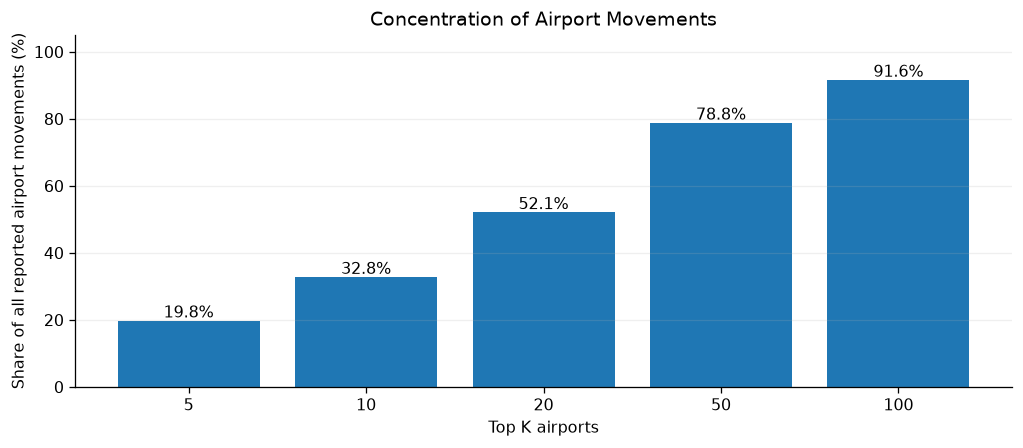

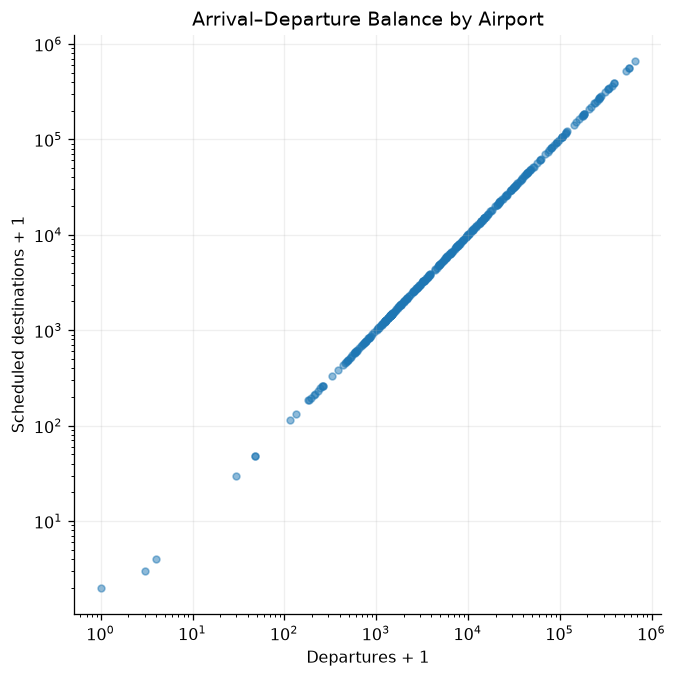

High-imbalance airports with >= 200 movements:


airport_id,airport,departures,arrivals,total,imbalance_ratio
i64,str,u32,u32,u32,f64
14222,"""PPG""",196,195,391,1.0985e7
15008,"""STC""",229,228,457,9.3982e6
14905,"""SMX""",246,245,491,8.7474e6
12177,"""HOB""",261,260,521,8.2437e6
10272,"""ALS""",261,260,521,8.2437e6
…,…,…,…,…,…
11471,"""EAU""",489,488,977,4.3961e6
10967,"""CGI""",515,514,1029,4.1739e6
14288,"""PUB""",527,526,1053,4.0788e6


In [12]:
airport_ranked = airport_counts.sort("total", descending=True)
ks = [5, 10, 20, 50, 100]
shares = [100 * airport_ranked.head(k)["total"].sum() / airport_ranked["total"].sum() for k in ks]
plt.figure(figsize=(9, 4))
plt.bar([str(k) for k in ks], shares)
for i, s in enumerate(shares):
    plt.text(i, s + 1, f"{s:.1f}%", ha="center")
plt.ylim(0, 105)
plt.title("Concentration of Airport Movements")
plt.xlabel("Top K airports")
plt.ylabel("Share of all reported airport movements (%)")
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

airport_balance = airport_counts.with_columns(
    ((pl.col("arrivals") - pl.col("departures")).abs() / pl.col("total")).alias("imbalance_ratio")
)
plt.figure(figsize=(6, 6))
plt.scatter(airport_counts["departures"].to_numpy()+1,
            airport_counts["arrivals"].to_numpy()+1, alpha=.5, s=18)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Departures + 1")
plt.ylabel("Scheduled destinations + 1")
plt.title("Arrival–Departure Balance by Airport")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

print("High-imbalance airports with >= 200 movements:")
display(airport_balance.filter(pl.col("total") >= 200).sort("imbalance_ratio", descending=True).head(12))


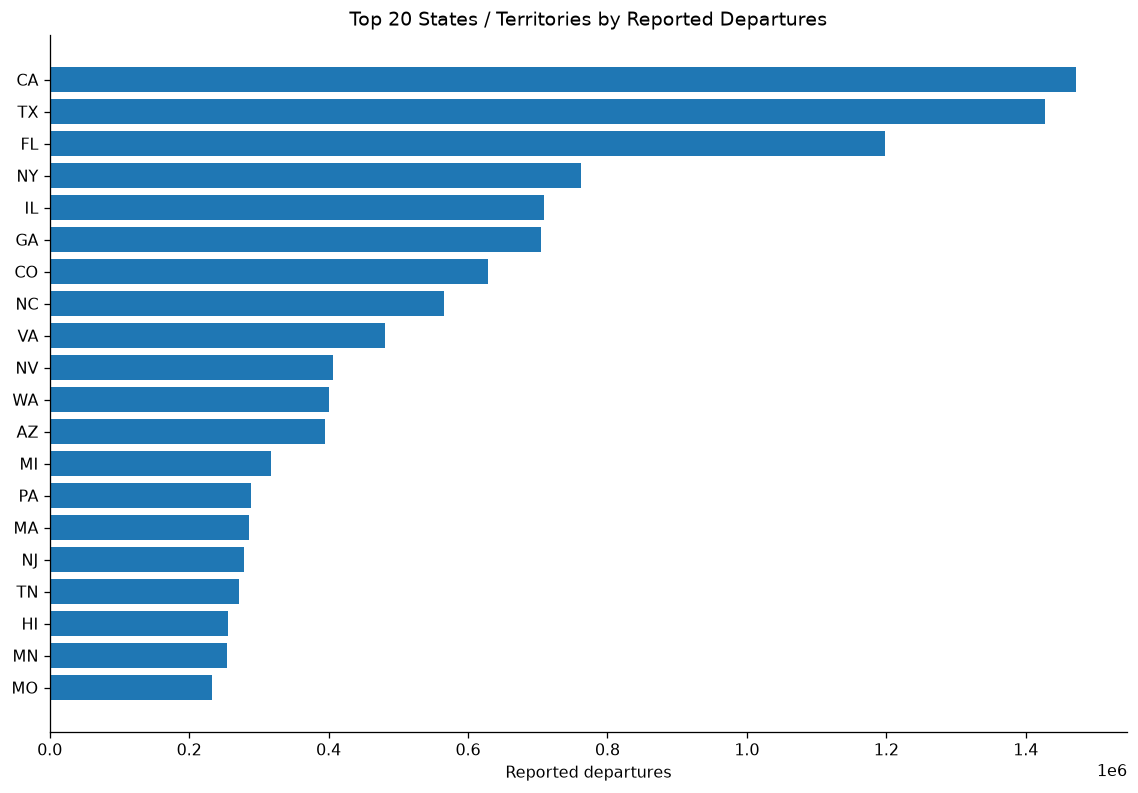

States / territories represented: 53
Missing state codes:  0


In [13]:
state_volume = (
    df.group_by("ORIGIN_STATE_ABR")
    .agg(pl.len().alias("departures"), pl.col("ORIGIN_AIRPORT_ID").n_unique().alias("airports"))
    .sort("departures", descending=True).collect(engine="streaming")
)
state_top = state_volume.head(20).sort("departures")
plt.figure(figsize=(10, 7))
plt.barh(state_top["ORIGIN_STATE_ABR"].to_list(), state_top["departures"].to_list())
plt.title("Top 20 States / Territories by Reported Departures")
plt.xlabel("Reported departures")
plt.tight_layout()
plt.show()

print("States / territories represented:", state_volume.height)
print("Missing state codes: ", df.select(pl.col("ORIGIN_STATE_ABR").is_null().sum()).collect(engine="streaming").item())


**IFP exception (DOT 10590).** A previous analysis identified one reported BIL → IFP flight on 2022-09-11 (G4 638, aircraft `246NV`), with `DEP_DELAY=-9` and `ARR_DELAY=222`. The implied actual duration is 369 minutes against 138 scheduled. Retain for investigation; the operational cause is unknown.

In [14]:
if 10590 in destinations:
    ifp_case = df.filter(pl.col("DEST_AIRPORT_ID") == 10590).select(
        "FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "TAIL_NUM", "ORIGIN", "DEST",
        "CRS_DEP_TIME", "DEP_TIME", "CRS_ARR_TIME", "ARR_TIME",
        "CRS_ELAPSED_TIME", "DEP_DELAY", "ARR_DELAY", "CANCELLED", "DIVERTED",
    ).collect(engine="streaming")
    display(ifp_case)
else:
    print("IFP (10590) is absent from this dataset version.")


FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,TAIL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,CRS_ARR_TIME,ARR_TIME,CRS_ELAPSED_TIME,DEP_DELAY,ARR_DELAY,CANCELLED,DIVERTED
datetime[ns],str,i64,str,str,str,i64,i64,i64,i64,f64,f64,f64,f64,f64
2022-09-11 00:00:00,"""G4""",638,"""246NV""","""BIL""","""IFP""",2031,2022,2149,131,138.0,-9.0,222.0,0.0,0.0


## 1.6 Routes

Routes are directed origin–destination pairs. Flight frequency and the number of distinct connections are different measures.

Directed routes: 7163
Routes with ≤ 10 flights: 292
Routes with ≤ 100 flights: 1147
Share of flights in top 20 routes (%): 2.93


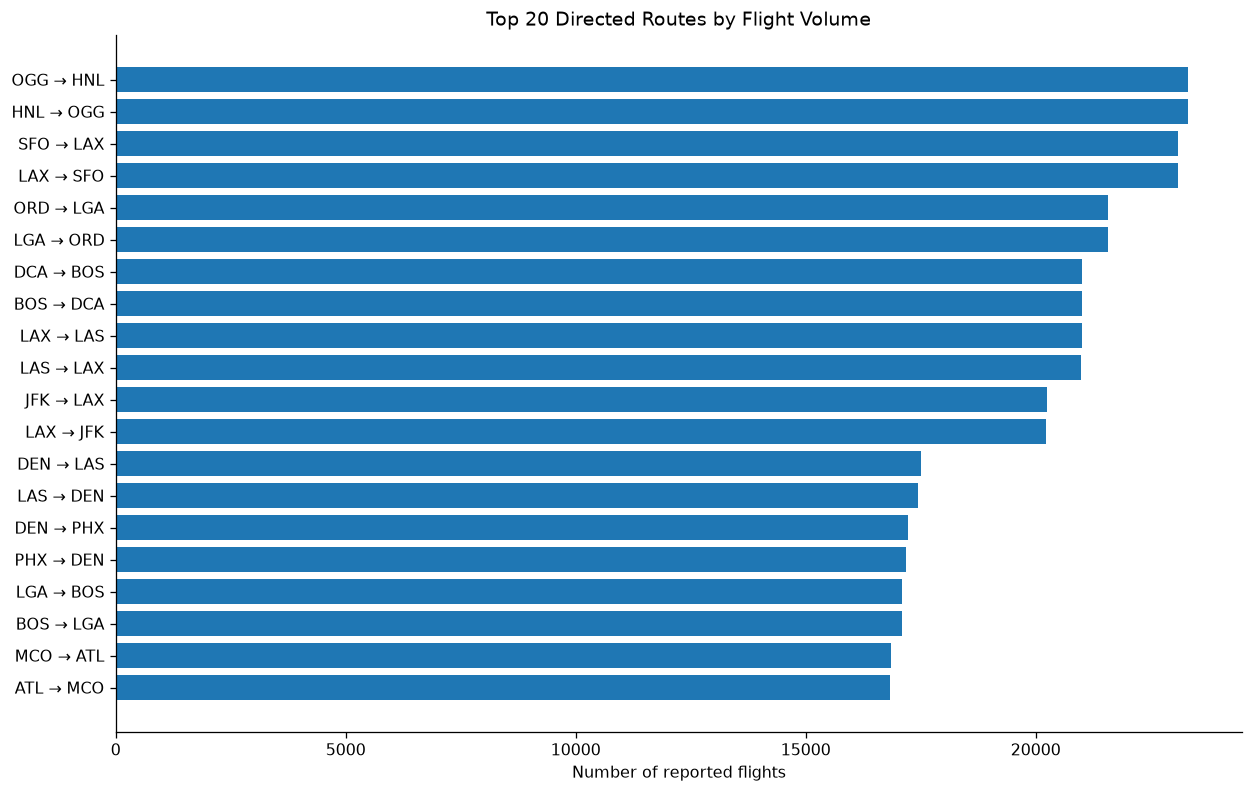

In [15]:
route_counts = (
    df.group_by("ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID")
    .agg(pl.len().alias("flights"),
         pl.col("ORIGIN").first().alias("ORIGIN"),
         pl.col("DEST").first().alias("DEST"))
    .sort("flights", descending=True)
    .collect(engine="streaming")
    .with_columns((pl.col("ORIGIN") + " → " + pl.col("DEST")).alias("route"))
)

print("Directed routes:", route_counts.height)
print("Routes with ≤ 10 flights:", route_counts.filter(pl.col("flights") <= 10).height)
print("Routes with ≤ 100 flights:", route_counts.filter(pl.col("flights") <= 100).height)
print("Share of flights in top 20 routes (%):",
      round(100 * route_counts.head(20)["flights"].sum() / route_counts["flights"].sum(), 2))

top_routes = route_counts.head(20).sort("flights")
plt.figure(figsize=(11, 7))
plt.barh(top_routes["route"].to_list(), top_routes["flights"].to_list())
plt.title("Top 20 Directed Routes by Flight Volume")
plt.xlabel("Number of reported flights")
plt.tight_layout()
plt.show()


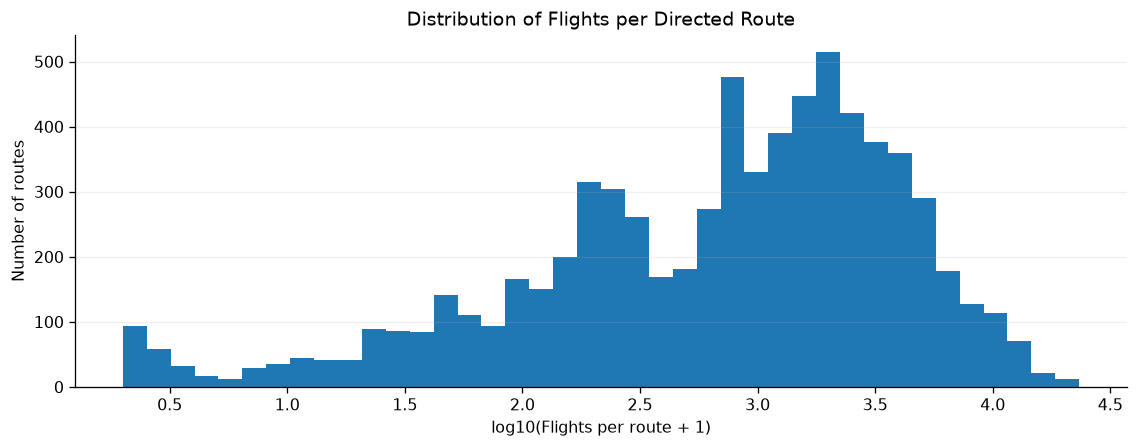

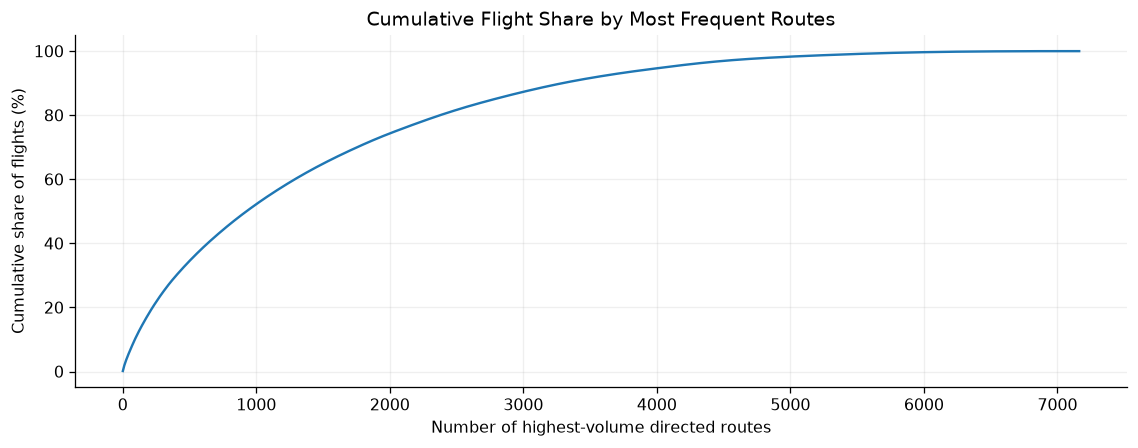

In [16]:
route_volumes = route_counts["flights"].to_numpy()
plt.figure(figsize=(10, 4))
plt.hist(np.log10(route_volumes + 1), bins=40)
plt.title("Distribution of Flights per Directed Route")
plt.xlabel("log10(Flights per route + 1)")
plt.ylabel("Number of routes")
plt.grid(axis="y",alpha=.2)
plt.tight_layout()
plt.show()

ranked = route_counts.sort("flights", descending=True).with_columns(
    (pl.col("flights").cum_sum() / pl.col("flights").sum() * 100).alias("cumulative_share")
)
plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, ranked.height + 1), ranked["cumulative_share"].to_numpy())
plt.title("Cumulative Flight Share by Most Frequent Routes")
plt.xlabel("Number of highest-volume directed routes")
plt.ylabel("Cumulative share of flights (%)")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()


In [17]:
# Reciprocity: reverse routes exist, but may have different volumes.
route_keys = set(zip(route_counts["ORIGIN_AIRPORT_ID"].to_list(),
                     route_counts["DEST_AIRPORT_ID"].to_list()))
reciprocal = sum((b, a) in route_keys for a, b in route_keys)
print(f"Directed routes with a reverse route: {reciprocal}/{len(route_keys)} ({reciprocal / len(route_keys):.1%})")

# Compare route presence across years, not schedules.
route_year_keys = (
    df.group_by("YEAR", "ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID")
    .agg(pl.len().alias("flights")).collect(engine="streaming")
)
per_year_routes = {
    year: set(zip(t["ORIGIN_AIRPORT_ID"].to_list(), t["DEST_AIRPORT_ID"].to_list()))
    for year, t in ((yr, route_year_keys.filter(pl.col("YEAR") == yr)) for yr in [2022, 2023])
}
shared = per_year_routes[2022] & per_year_routes[2023]
union = per_year_routes[2022] | per_year_routes[2023]
print("Routes 2022:", len(per_year_routes[2022]))
print("Routes 2023:", len(per_year_routes[2023]))
print("Routes in both years:", len(shared))
print("Jaccard route-set similarity:", round(len(shared) / len(union), 3) if union else None)


Directed routes with a reverse route: 7122/7163 (99.4%)
Routes 2022: 6872
Routes 2023: 6596
Routes in both years: 6305
Jaccard route-set similarity: 0.88


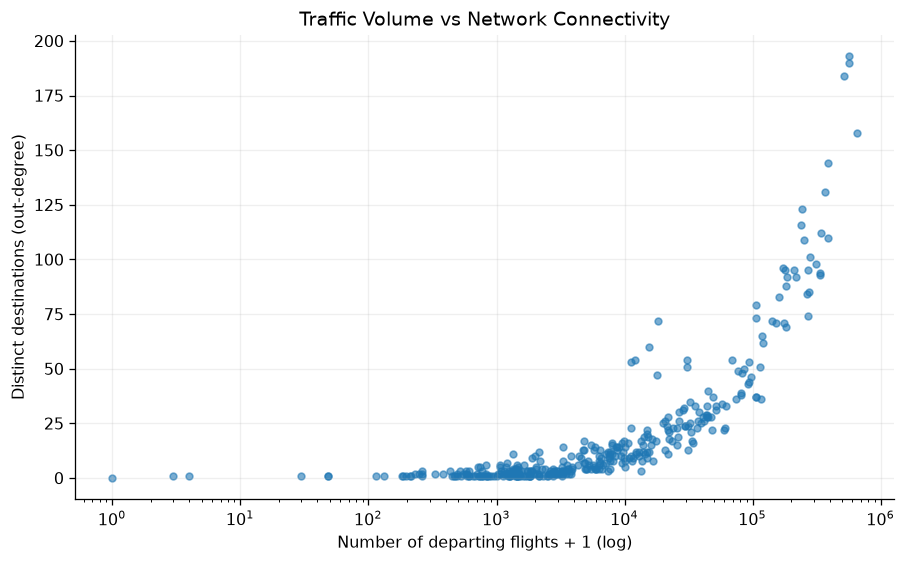

In [18]:
# Count distinct inbound and outbound routes.
node_out = route_counts.group_by("ORIGIN_AIRPORT_ID").agg(
    pl.len().alias("out_degree")
).rename({"ORIGIN_AIRPORT_ID": "airport_id"})
node_in = route_counts.group_by("DEST_AIRPORT_ID").agg(
    pl.len().alias("in_degree")
).rename({"DEST_AIRPORT_ID": "airport_id"})
airport_degree = (
    airport_counts.join(node_out, on="airport_id", how="left")
    .join(node_in, on="airport_id", how="left")
    .with_columns(pl.col("out_degree").fill_null(0), pl.col("in_degree").fill_null(0))
)

plt.figure(figsize=(8, 5))
plt.scatter(airport_degree["departures"].to_numpy()+1,
            airport_degree["out_degree"].to_numpy(), alpha=.6, s=18)
plt.xscale("log")
plt.xlabel("Number of departing flights + 1 (log)")
plt.ylabel("Distinct destinations (out-degree)")
plt.title("Traffic Volume vs Network Connectivity")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()


## 1.7 Airlines

Airlines: 17
Top 5 share (%): 67.8


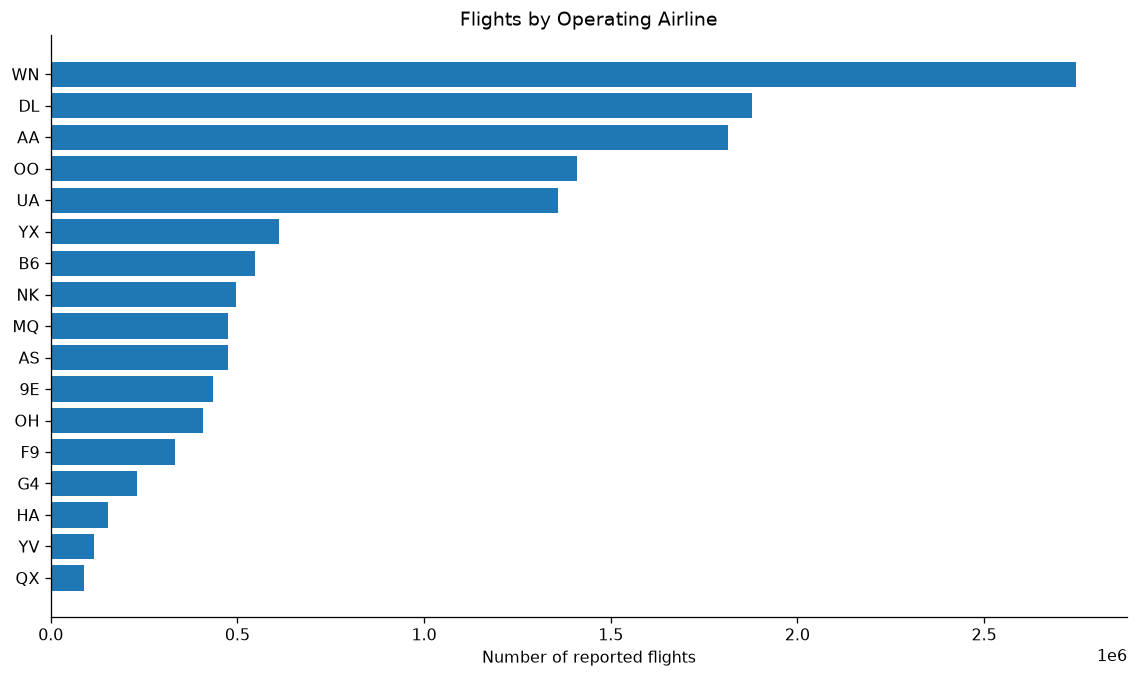

In [19]:
airline_counts = (
    df.group_by("OP_UNIQUE_CARRIER")
    .agg(
        pl.len().alias("flights"),
        pl.col("ORIGIN_AIRPORT_ID").n_unique().alias("origin_airports"),
        pl.col("DEST_AIRPORT_ID").n_unique().alias("destination_airports"),
        pl.struct(["ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID"]).n_unique().alias("routes"),
        pl.col("TAIL_NUM").drop_nulls().n_unique().alias("aircraft_observed"),
    )
    .sort("flights", descending=True)
    .collect(engine="streaming")
    .with_columns((100 * pl.col("flights") / pl.col("flights").sum()).alias("pct_flights"))
)

print("Airlines:", airline_counts.height)
print("Top 5 share (%):", round(airline_counts.head(5)["pct_flights"].sum(), 1))
airline_sorted = airline_counts.sort("flights")
plt.figure(figsize=(10, 6))
plt.barh(airline_sorted["OP_UNIQUE_CARRIER"].to_list(), airline_sorted["flights"].to_list())
plt.title("Flights by Operating Airline")
plt.xlabel("Number of reported flights")
plt.tight_layout()
plt.show()


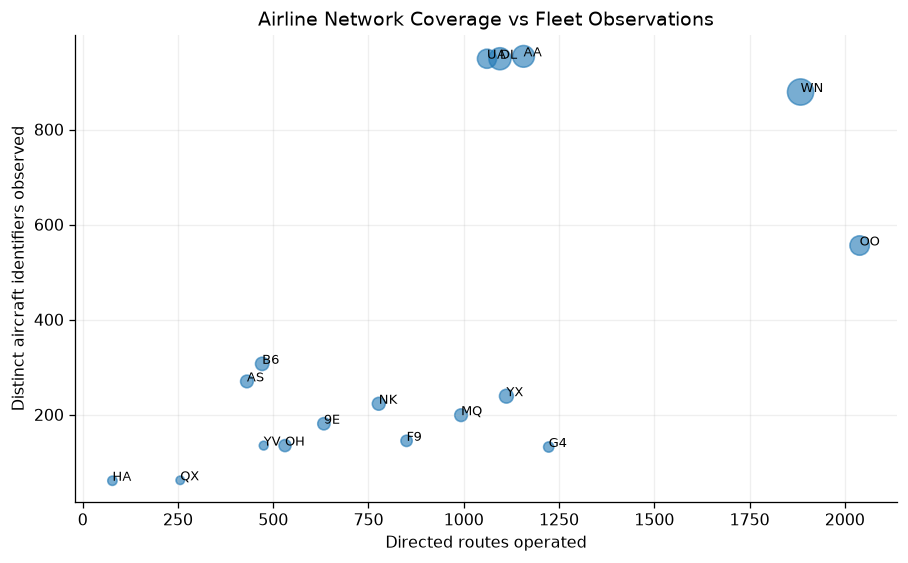

In [20]:
# Compare route and observed aircraft coverage by airline.
plt.figure(figsize=(8, 5))
plt.scatter(airline_counts["routes"].to_numpy(), airline_counts["aircraft_observed"].to_numpy(),
            s=airline_counts["flights"].to_numpy() / airline_counts["flights"].max() * 250 + 20,
            alpha=.6)
for r in airline_counts.iter_rows(named=True):
    plt.annotate(r["OP_UNIQUE_CARRIER"], (r["routes"], r["aircraft_observed"]), fontsize=8)
plt.xlabel("Directed routes operated")
plt.ylabel("Distinct aircraft identifiers observed")
plt.title("Airline Network Coverage vs Fleet Observations")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()


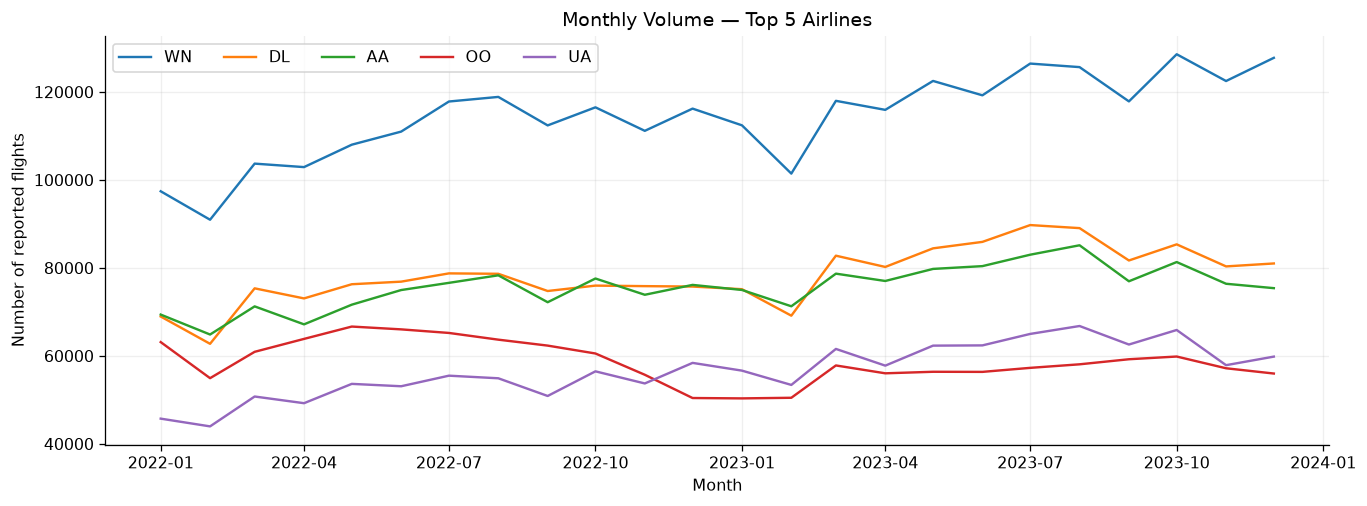

In [21]:
top_airline_codes = airline_counts.head(5)["OP_UNIQUE_CARRIER"].to_list()
airline_monthly = (
    df.filter(pl.col("OP_UNIQUE_CARRIER").is_in(top_airline_codes))
    .group_by("YEAR", "MONTH", "OP_UNIQUE_CARRIER")
    .agg(pl.len().alias("flights"))
    .collect(engine="streaming")
    .with_columns(pl.date("YEAR", "MONTH", pl.lit(1)).alias("period"))
)
plt.figure(figsize=(12, 4.5))
for carrier in top_airline_codes:
    v = airline_monthly.filter(pl.col("OP_UNIQUE_CARRIER") == carrier).sort("period")
    plt.plot(v["period"].to_list(), v["flights"].to_list(), label=carrier)
plt.title("Monthly Volume — Top 5 Airlines")
plt.xlabel("Month")
plt.ylabel("Number of reported flights")
plt.legend(ncol=5)
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()


## 1.8 Aircraft

`TAIL_NUM` is the observed aircraft identifier; the data may not cover every flight operated by an aircraft.

Distinct nonempty TAIL_NUM: 6360
Missing/empty TAIL_NUM rows: 50046


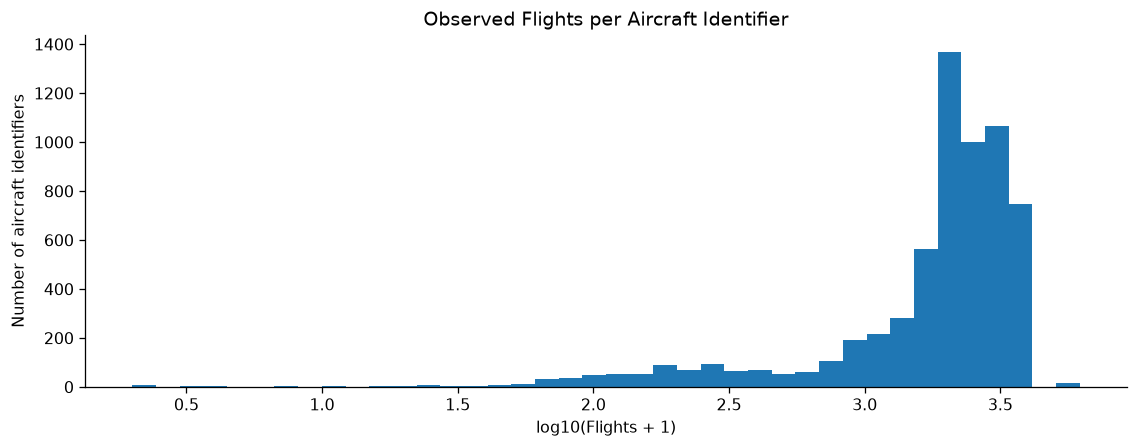

In [22]:
identified_aircraft_flights = df.filter(pl.col("TAIL_NUM").is_not_null() & (pl.col("TAIL_NUM") != ""))

aircraft_counts = (
    identified_aircraft_flights.group_by("TAIL_NUM")
    .agg(
        pl.len().alias("flights"),
        pl.col("FL_DATE").n_unique().alias("active_dates"),
        pl.struct(["ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID"]).n_unique().alias("routes"),
        pl.col("OP_UNIQUE_CARRIER").n_unique().alias("airlines"),
    )
    .collect(engine="streaming")
)

missing_tail = df.select(
    (pl.col("TAIL_NUM").is_null() | (pl.col("TAIL_NUM") == "")).sum().alias("missing_tail")
).collect(engine="streaming")["missing_tail"][0]
print("Distinct nonempty TAIL_NUM:", aircraft_counts.height)
print("Missing/empty TAIL_NUM rows:", missing_tail)

plt.figure(figsize=(10, 4))
plt.hist(np.log10(aircraft_counts["flights"].to_numpy() + 1), bins=40)
plt.title("Observed Flights per Aircraft Identifier")
plt.xlabel("log10(Flights + 1)")
plt.ylabel("Number of aircraft identifiers")
plt.tight_layout()
plt.show()


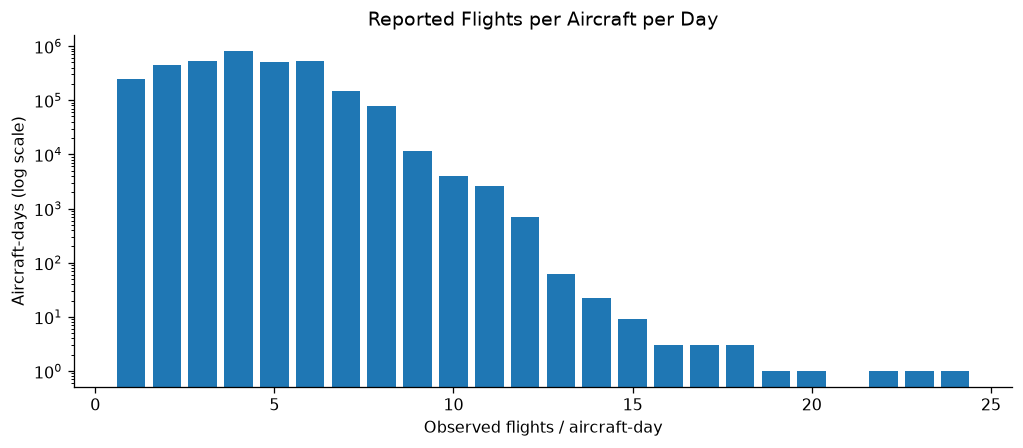

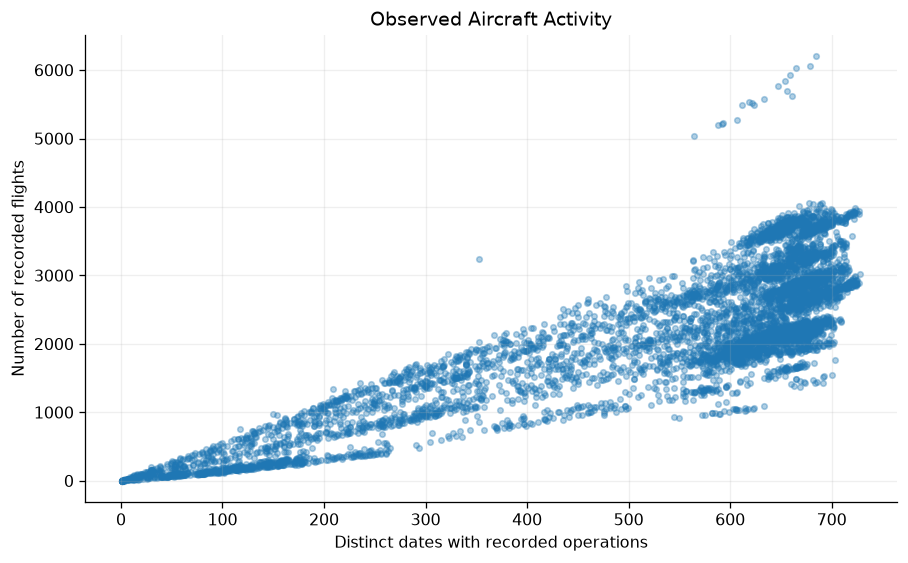

In [23]:
aircraft_daily = (
    identified_aircraft_flights.group_by("TAIL_NUM", "FL_DATE")
    .agg(pl.len().alias("flights_per_day"))
    .collect(engine="streaming")
)
per_day_distribution = aircraft_daily.group_by("flights_per_day").agg(
    pl.len().alias("aircraft_days")
).sort("flights_per_day")
plt.figure(figsize=(9, 4))
plt.bar(per_day_distribution["flights_per_day"].to_list(),
        per_day_distribution["aircraft_days"].to_list())
plt.yscale("log")
plt.title("Reported Flights per Aircraft per Day")
plt.xlabel("Observed flights / aircraft-day")
plt.ylabel("Aircraft-days (log scale)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(aircraft_counts["active_dates"].to_numpy(),
            aircraft_counts["flights"].to_numpy(), s=12, alpha=.35)
plt.xlabel("Distinct dates with recorded operations")
plt.ylabel("Number of recorded flights")
plt.title("Observed Aircraft Activity")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()


### Aircraft example: `246NV`

The reported itinerary on 2022-09-11 includes `AZA → PIA → AZA → BIL → IFP`. Local departure times alone cannot establish a validated UTC sequence.

In [24]:
sample_aircraft = (
    df.filter((pl.col("TAIL_NUM") == "246NV") &
              (pl.col("FL_DATE").dt.date() == date(2022, 9, 11)))
    .select("FL_DATE", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST",
            "CRS_DEP_TIME", "DEP_TIME", "CRS_ARR_TIME", "ARR_TIME",
            "DEP_DELAY", "ARR_DELAY", "CANCELLED", "DIVERTED")
    .sort("CRS_DEP_TIME")
    .collect(engine="streaming")
)
display(sample_aircraft)
print("Ordering uses local departure times, not a validated UTC chronology.")


FL_DATE,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,CRS_ARR_TIME,ARR_TIME,DEP_DELAY,ARR_DELAY,CANCELLED,DIVERTED
datetime[ns],i64,str,str,i64,i64,i64,i64,f64,f64,f64,f64
2022-09-11 00:00:00,684,"""AZA""","""PIA""",750,745,1252,1240,-5.0,-12.0,0.0,0.0
2022-09-11 00:00:00,688,"""PIA""","""AZA""",1337,1407,1454,1528,30.0,34.0,0.0,0.0
2022-09-11 00:00:00,637,"""AZA""","""BIL""",1628,1629,1946,1940,1.0,-6.0,0.0,0.0
2022-09-11 00:00:00,638,"""BIL""","""IFP""",2031,2022,2149,131,-9.0,222.0,0.0,0.0


Ordering uses local departure times, not a validated UTC chronology.


## 1.9 Arrival Delay Definition

A completed flight is delayed when `ARR_DELAY >= 15` minutes. The analysis of arrival delays excludes cancelled flights, diverted flights and records without a known arrival delay; excluded cases are assessed separately.

In [25]:
# Separate operational statuses when checking eligibility.
status = (
    df.with_columns(
        pl.when(pl.col("CANCELLED") == 1).then(pl.lit("cancelled"))
        .when(pl.col("DIVERTED") == 1).then(pl.lit("diverted"))
        .when(pl.col("CANCELLED").is_null() | pl.col("DIVERTED").is_null())
        .then(pl.lit("missing_status"))
        .when(pl.col("ARR_DELAY").is_null()).then(pl.lit("missing_arrival_delay"))
        .otherwise(pl.lit("eligible_arrival"))
        .alias("target_status")
    )
    .group_by("target_status").agg(pl.len().alias("flights"))
    .collect(engine="streaming")
)
status = status.with_columns((pl.col("flights") / pl.col("flights").sum() * 100).alias("percent"))
display(status.sort("flights", descending=True))

eligible = df.filter(
    (pl.col("CANCELLED") == 0) &
    (pl.col("DIVERTED") == 0) &
    pl.col("ARR_DELAY").is_not_null()
)
labelled_flights = eligible.with_columns(
    (pl.col("ARR_DELAY") >= 15).cast(pl.Int8).alias("TARGET_DELAY_15")
)


target_status,flights,percent
str,u32,f64
"""eligible_arrival""",13275415,97.778534
"""cancelled""",269229,1.982975
"""diverted""",32378,0.238476
"""missing_arrival_delay""",2,0.000015


## 1.10 Timing and Data Availability

Scheduled flight fields are available before operations; actual departure, taxi and arrival measurements describe events observed later. Aircraft assignments and recent operating information may not be available at every point in time. Avoid treating retrospective fields as information available in advance.

## 1.11 Data Quality

Inspect missingness, duplicate candidates, consistency checks and extreme values without modifying the source records.

Columns with any missing observations: 11


column,missing,missing_pct
str,i64,f64
"""TOTAL_ADD_GTIME""",13492227,99.375438
"""LONGEST_ADD_GTIME""",13492227,99.375438
"""FIRST_DEP_TIME""",13492222,99.375401
"""ARR_DELAY""",301609,2.221466
"""TAXI_IN""",272578,2.007642
…,…,…
"""TAXI_OUT""",267794,1.972406
"""DEP_DELAY""",261877,1.928825
"""DEP_TIME""",261738,1.927801


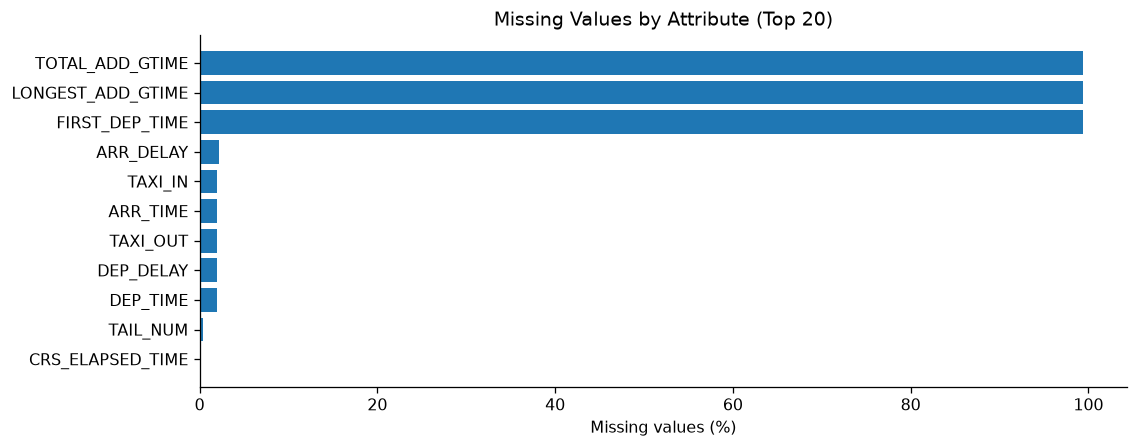

In [26]:
null_aggs = [pl.col(col).is_null().sum().alias(col) for col in actual_schema]
null_wide = df.select(null_aggs).collect(engine="streaming")
null_counts = pl.DataFrame({
    "column": list(actual_schema),
    "missing": [int(null_wide[col][0]) for col in actual_schema],
}).with_columns((100 * pl.col("missing") / int(overview["flights"][0])).alias("missing_pct"))

nonzero_nulls = null_counts.filter(pl.col("missing") > 0).sort("missing_pct", descending=True)
print("Columns with any missing observations:", nonzero_nulls.height)
display(nonzero_nulls)

if nonzero_nulls.height:
    t = nonzero_nulls.head(20).sort("missing_pct")
    plt.figure(figsize=(10, max(4, .32 * t.height)))
    plt.barh(t["column"].to_list(), t["missing_pct"].to_list())
    plt.title("Missing Values by Attribute (Top 20)")
    plt.xlabel("Missing values (%)")
    plt.tight_layout()
    plt.show()


In [27]:
missing_by_status = (
    df.with_columns(
        pl.when(pl.col("CANCELLED") == 1).then(pl.lit("cancelled"))
        .when(pl.col("DIVERTED") == 1).then(pl.lit("diverted"))
        .otherwise(pl.lit("neither"))
        .alias("status")
    )
    .group_by("status")
    .agg(
        pl.len().alias("flights"),
        (pl.col("ARR_DELAY").is_null().mean() * 100).alias("missing_arr_delay_pct"),
        (pl.col("DEP_DELAY").is_null().mean() * 100).alias("missing_dep_delay_pct"),
        (pl.col("TAIL_NUM").is_null().mean() * 100).alias("missing_tail_pct"),
    )
    .collect(engine="streaming")
)
display(missing_by_status)


status,flights,missing_arr_delay_pct,missing_dep_delay_pct,missing_tail_pct
str,u32,f64,f64,f64
"""neither""",13275417,0.000015,0.0,0.0
"""diverted""",32378,100.0,0.0,0.0
"""cancelled""",269229,100.0,97.269239,18.588636


### Missingness Patterns

Assess whether missing fields are associated with flight status, year or airline. Operational fields can be structurally unavailable for cancelled or diverted flights; missing values on completed flights require separate investigation. Percentages use the number of flights in each group.

In [28]:
# Overall missingness, including NaN values in floating-point fields.
float_types = {pl.Float32, pl.Float64}
missing_exprs = [
    (pl.col(col).is_null() | pl.col(col).is_nan().fill_null(False)).sum().alias(col)
    if dtype in float_types else pl.col(col).is_null().sum().alias(col)
    for col, dtype in df.collect_schema().items()
]
missing_all = df.select(missing_exprs).collect(engine="streaming")
missing_all = pl.DataFrame({
    "column": list(df.collect_schema()),
    "missing_or_nan": [int(missing_all[c][0]) for c in df.collect_schema()],
}).with_columns((100 * pl.col("missing_or_nan") / int(overview["flights"][0])).alias("missing_pct"))
display(missing_all.sort("missing_pct", descending=True))

fields = ["ARR_DELAY", "DEP_DELAY", "ACTUAL_ELAPSED_TIME", "TAIL_NUM", "ARR_TIME", "DEP_TIME"]
fields = [c for c in fields if c in df.collect_schema()]
status_expr = (
    pl.when(pl.col("CANCELLED") == 1).then(pl.lit("cancelled"))
    .when(pl.col("DIVERTED") == 1).then(pl.lit("diverted"))
    .when(pl.col("CANCELLED").is_null() | pl.col("DIVERTED").is_null())
      .then(pl.lit("unknown_status"))
    .otherwise(pl.lit("not_cancelled_or_diverted"))
)
by_status_missing = (df.with_columns(status_expr.alias("flight_status"))
 .group_by("flight_status").agg(
     pl.len().alias("flights"),
     *[(pl.col(c).is_null().mean() * 100).alias(c) for c in fields]
 ).collect(engine="streaming"))
display(by_status_missing)

by_year_missing = (df.group_by("YEAR").agg(
    pl.len().alias("flights"),
    *[(pl.col(c).is_null().mean() * 100).alias(c) for c in fields]
).sort("YEAR").collect(engine="streaming"))
display(by_year_missing)

by_airline_missing = (df.group_by("OP_UNIQUE_CARRIER").agg(
    pl.len().alias("flights"),
    *[(pl.col(c).is_null().mean() * 100).alias(c) for c in fields]
).sort("flights", descending=True).collect(engine="streaming"))
display(by_airline_missing)


column,missing_or_nan,missing_pct
str,i64,f64
"""TOTAL_ADD_GTIME""",13492227,99.375438
"""LONGEST_ADD_GTIME""",13492227,99.375438
"""FIRST_DEP_TIME""",13492222,99.375401
"""ARR_DELAY""",301609,2.221466
"""TAXI_IN""",272578,2.007642
…,…,…
"""DIVERTED""",0,0.0
"""FLIGHTS""",0,0.0
"""DISTANCE""",0,0.0


flight_status,flights,ARR_DELAY,DEP_DELAY,TAIL_NUM,ARR_TIME,DEP_TIME
str,u32,f64,f64,f64,f64,f64
"""not_cancelled_or_diverted""",13275417,0.000015,0.0,0.0,0.000015,0.0
"""cancelled""",269229,100.0,97.269239,18.588636,100.0,97.21761
"""diverted""",32378,100.0,0.0,0.0,10.324912,0.0


YEAR,flights,ARR_DELAY,DEP_DELAY,TAIL_NUM,ARR_TIME,DEP_TIME
i64,u32,f64,f64,f64,f64,f64
2022,6729125,2.929252,2.635528,0.513588,2.718808,2.634354
2023,6847899,1.525957,1.234379,0.226142,1.308752,1.233502


OP_UNIQUE_CARRIER,flights,ARR_DELAY,DEP_DELAY,TAIL_NUM,ARR_TIME,DEP_TIME
str,u32,f64,f64,f64,f64,f64
"""WN""",2745614,2.276758,2.054477,0.354784,2.098001,2.054477
"""DL""",1878158,1.492686,1.259798,0.013577,1.305215,1.259798
"""AA""",1814676,2.241778,1.911581,0.017193,1.990658,1.911581
"""OO""",1408739,1.819287,1.496374,0.027968,1.583118,1.494031
"""UA""",1358685,1.888885,1.572329,1.572329,1.649831,1.572329
…,…,…,…,…,…,…
"""F9""",333024,2.648157,2.375504,2.374003,2.492613,2.374303
"""G4""",232416,2.377203,2.080752,1.753752,2.128511,2.037725
"""HA""",154832,1.219386,1.096027,1.096027,1.129611,1.096027


In [29]:
# Joint missingness patterns: these fields frequently share a common operational reason.
pattern_fields = [c for c in ["ARR_TIME", "ARR_DELAY", "ACTUAL_ELAPSED_TIME", "DEP_DELAY"]
                  if c in df.collect_schema()]
patterns = (df.select([pl.col(c).is_null().cast(pl.Int8).alias(c) for c in pattern_fields])
            .group_by(pattern_fields).agg(pl.len().alias("flights"))
            .sort("flights", descending=True).head(12).collect(engine="streaming"))
display(patterns)
# Eligible observations lacking a label, and percentage of flights excluded by status.
filter_audit = (df.select(
    pl.len().alias("all_flights"),
    (pl.col("CANCELLED") == 1).sum().alias("cancelled"),
    (pl.col("DIVERTED") == 1).sum().alias("diverted"),
    ((pl.col("CANCELLED") == 0) & (pl.col("DIVERTED") == 0)
     & pl.col("ARR_DELAY").is_null()).sum().alias("missing_label_after_status_filter"),
).collect(engine="streaming"))
for name in ["cancelled", "diverted", "missing_label_after_status_filter"]:
    count = int(filter_audit[name][0]); total = int(filter_audit["all_flights"][0])
    print(f"{name}: {count:,} ({100 * count / total:.2f}%)")


ARR_TIME,ARR_DELAY,DEP_DELAY,flights
i8,i8,i8,u32
0,0,0,13275415
1,1,1,261877
0,1,0,29035
1,1,0,10697


cancelled: 269,229 (1.98%)
diverted: 32,378 (0.24%)
missing_label_after_status_filter: 2 (0.00%)


In [30]:
# Duplicate candidates based on an unverified composite key.
# Hash collisions are possible; this is an approximate check.
CANDIDATE_KEY = [
    "FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM",
    "ORIGIN_AIRPORT_ID", "DEST_AIRPORT_ID", "CRS_DEP_TIME"
]
unique_candidate_hashes = df.select(
    pl.struct(CANDIDATE_KEY).hash(seed=2026).n_unique().alias("unique_key_hashes")
).collect(engine="streaming")["unique_key_hashes"][0]

candidate_duplicate_excess = int(overview["flights"][0]) - int(unique_candidate_hashes)
print("Excess rows under candidate-key 64-bit fingerprint (approx.):", candidate_duplicate_excess)
print("Repetition of the candidate key is not proof of full-row duplicates.")

# Optional: grouping nearly 14M keys may be expensive.
RUN_DETAILED_DUPLICATE_SCAN = False
if RUN_DETAILED_DUPLICATE_SCAN:
    duplicate_groups = (
        df.group_by(CANDIDATE_KEY)
        .agg(pl.len().alias("n"))
        .filter(pl.col("n") > 1)
        .collect(engine="streaming")
    )
    print("Candidate-key groups with repeated rows:", duplicate_groups.height)
    if duplicate_groups.height:
        display(duplicate_groups.sort("n", descending=True).head(12))
else:
    print("Detailed duplicate-key grouping skipped (set RUN_DETAILED_DUPLICATE_SCAN=True if needed).")


Excess rows under candidate-key 64-bit fingerprint (approx.): 0
Repetition of the candidate key is not proof of full-row duplicates.
Detailed duplicate-key grouping skipped (set RUN_DETAILED_DUPLICATE_SCAN=True if needed).


In [31]:
# Check value consistency; count nulls separately.

def invalid_hhmm(col):
    v = pl.col(col)
    # Some time conventions permit 24:00.
    return v.is_not_null() & (
        (v < 0)
        | (v > 2400)
        | ((v % 100) >= 60)
        | (((v // 100) == 24) & (v != 2400))
    )

def invalid_integer_range(col, lower, upper):
    v = pl.col(col)
    return v.is_not_null() & (
        (~v.is_between(lower, upper)) | (v % 1 != 0)
    )

def invalid_binary(col):
    v = pl.col(col)
    return v.is_not_null() & (
        (v != 0) & (v != 1)
    )

rules = {
    "YEAR_vs_FL_DATE": pl.col("FL_DATE").is_not_null() & (
        pl.col("FL_DATE").dt.year() != pl.col("YEAR")
    ),
    "MONTH_vs_FL_DATE": pl.col("FL_DATE").is_not_null() & (
        pl.col("FL_DATE").dt.month() != pl.col("MONTH")
    ),
    "DAY_vs_FL_DATE": pl.col("FL_DATE").is_not_null() & (
        pl.col("FL_DATE").dt.day() != pl.col("DAY_OF_MONTH")
    ),
    "WEEKDAY_vs_FL_DATE": pl.col("FL_DATE").is_not_null() & (
        pl.col("FL_DATE").dt.weekday() != pl.col("DAY_OF_WEEK")
    ),
    "INVALID_QUARTER": invalid_integer_range("QUARTER", 1, 4),
    "INVALID_MONTH": invalid_integer_range("MONTH", 1, 12),
    "INVALID_CANCELLED": invalid_binary("CANCELLED"),
    "INVALID_DIVERTED": invalid_binary("DIVERTED"),
    "INVALID_CRS_DEP_HHMM": invalid_hhmm("CRS_DEP_TIME"),
    "INVALID_CRS_ARR_HHMM": invalid_hhmm("CRS_ARR_TIME"),
    "NONPOSITIVE_CRS_ELAPSED": (
        pl.col("CRS_ELAPSED_TIME").is_not_null()
        & (pl.col("CRS_ELAPSED_TIME") <= 0)
    ),
    "NEGATIVE_DISTANCE": (
        pl.col("DISTANCE").is_not_null()
        & (pl.col("DISTANCE") < 0)
    ),
    "MISSING_ORIGIN_ID": pl.col("ORIGIN_AIRPORT_ID").is_null(),
    "MISSING_DEST_ID": pl.col("DEST_AIRPORT_ID").is_null(),
}

quality_wide = df.select([
    expr.fill_null(False).sum().alias(name)
    for name, expr in rules.items()
]).collect(engine="streaming")

quality_summary = pl.DataFrame({
    "rule": list(rules),
    "flagged_rows": [int(quality_wide[k][0]) for k in rules],
}).sort("flagged_rows", descending=True)

display(quality_summary)
print("These are diagnostic flags, not automatic deletion rules.")

rule,flagged_rows
str,i64
"""NONPOSITIVE_CRS_ELAPSED""",6
"""YEAR_vs_FL_DATE""",0
"""MONTH_vs_FL_DATE""",0
"""DAY_vs_FL_DATE""",0
"""WEEKDAY_vs_FL_DATE""",0
…,…
"""INVALID_CRS_DEP_HHMM""",0
"""INVALID_CRS_ARR_HHMM""",0
"""NEGATIVE_DISTANCE""",0


These are diagnostic flags, not automatic deletion rules.


In [32]:
# Inspect extreme values without imputation or removal.
NUMERIC_AUDIT = ["ARR_DELAY", "DEP_DELAY", "CRS_ELAPSED_TIME", "DISTANCE", "TAXI_OUT", "TAXI_IN"]
quantile_exprs = []
for col in NUMERIC_AUDIT:
    for q, tag in [(0.01, "p01"), (0.50, "median"), (0.95, "p95"), (0.99, "p99")]:
        quantile_exprs.append(pl.col(col).quantile(q).alias(f"{col}_{tag}"))
quantiles = df.select(quantile_exprs).collect(engine="streaming")
display(quantiles)

# Duration identity, assuming valid delay fields:
# actual_elapsed = scheduled_elapsed + ARR_DELAY - DEP_DELAY.
# This algebraic identity does not independently validate the record.
print("Flagged IFP example remains retained. Outliers may be important for the target.")


ARR_DELAY_p01,ARR_DELAY_median,ARR_DELAY_p95,ARR_DELAY_p99,DEP_DELAY_p01,DEP_DELAY_median,DEP_DELAY_p95,DEP_DELAY_p99,CRS_ELAPSED_TIME_p01,CRS_ELAPSED_TIME_median,CRS_ELAPSED_TIME_p95,CRS_ELAPSED_TIME_p99,DISTANCE_p01,DISTANCE_median,DISTANCE_p95,DISTANCE_p99,TAXI_OUT_p01,TAXI_OUT_median,TAXI_OUT_p95,TAXI_OUT_p99,TAXI_IN_p01,TAXI_IN_median,TAXI_IN_p95,TAXI_IN_p99
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-36.0,-6.0,78.0,202.0,-13.0,-2.0,79.0,204.0,48.0,127.0,305.0,375.0,100.0,674.0,2182.0,2611.0,7.0,15.0,33.0,52.0,2.0,6.0,19.0,34.0


Flagged IFP example remains retained. Outliers may be important for the target.


## 1.12 Arrival Delay Distribution

Negative `ARR_DELAY` values indicate early arrival. Report both the frequency and magnitude of delays among eligible flights.

eligible_flights,delayed_15min,delayed_pct,mean_arr_delay,median_arr_delay
u32,i64,f64,f64,f64
13275415,2763497,20.816652,6.828148,-6.0


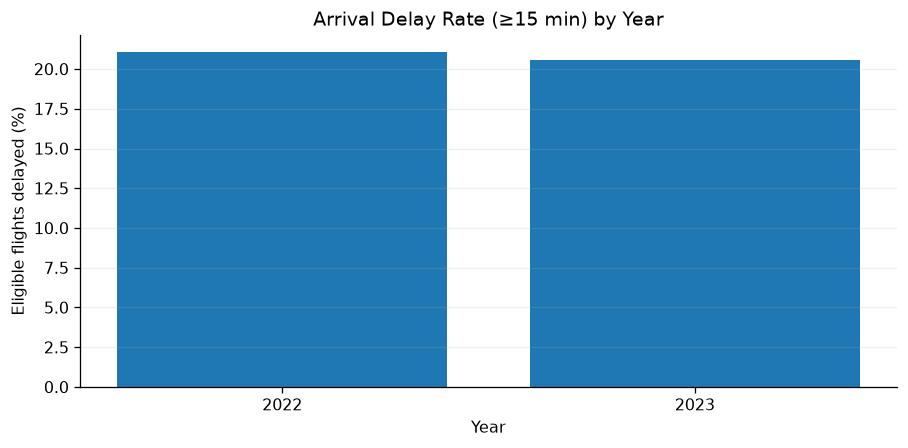

In [33]:
target_summary = labelled_flights.select(
    pl.len().alias("eligible_flights"),
    pl.col("TARGET_DELAY_15").sum().alias("delayed_15min"),
    (pl.col("TARGET_DELAY_15").mean() * 100).alias("delayed_pct"),
    pl.col("ARR_DELAY").mean().alias("mean_arr_delay"),
    pl.col("ARR_DELAY").median().alias("median_arr_delay"),
).collect(engine="streaming")
display(target_summary)

by_year_target = (
    labelled_flights.group_by("YEAR")
    .agg(pl.len().alias("flights"),
         (pl.col("TARGET_DELAY_15").mean() * 100).alias("delayed_pct"))
    .sort("YEAR").collect(engine="streaming")
)
plt.figure(figsize=(8, 4))
plt.bar([str(x) for x in by_year_target["YEAR"].to_list()], by_year_target["delayed_pct"].to_list())
plt.title("Arrival Delay Rate (≥15 min) by Year")
plt.xlabel("Year")
plt.ylabel("Eligible flights delayed (%)")
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()


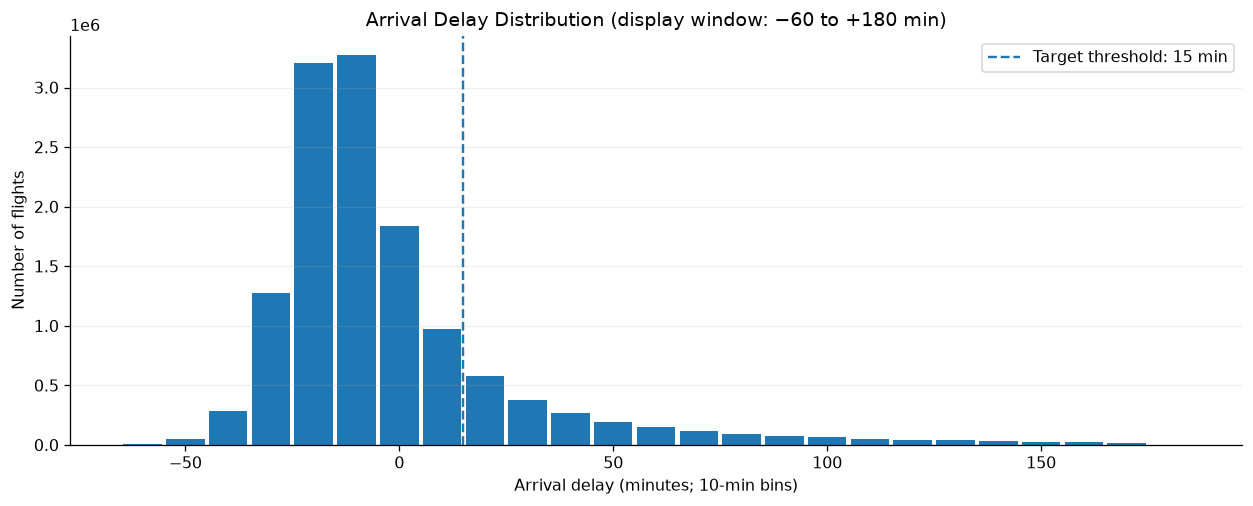

Important: tail events beyond the plotted window remain in the target calculations.


In [34]:
# Histogram uses 10-minute bins; tails are clipped only for display.
arrival_bins = (
    labelled_flights.filter(pl.col("ARR_DELAY").is_between(-60, 180))
    .with_columns(((pl.col("ARR_DELAY") // 10) * 10).cast(pl.Int32).alias("bin_start"))
    .group_by("bin_start").agg(pl.len().alias("flights"))
    .sort("bin_start")
    .collect(engine="streaming")
)
plt.figure(figsize=(11, 4.5))
plt.bar(arrival_bins["bin_start"].to_list(), arrival_bins["flights"].to_list(), width=9)
plt.axvline(15, linestyle="--", label="Target threshold: 15 min")
plt.title("Arrival Delay Distribution (display window: −60 to +180 min)")
plt.xlabel("Arrival delay (minutes; 10-min bins)")
plt.ylabel("Number of flights")
plt.legend()
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

print("Important: tail events beyond the plotted window remain in the target calculations.")


### Three-Class Arrival Delay Distribution

For completed flights with an observed `ARR_DELAY`, use the operational thresholds from `configs/config.yaml`. **Provisional definitions below:** `on_time` <15 min; `moderate_delay` 15–59 min; `severe_delay` ≥60 min. Confirm these cutoffs with Issues 1.3–1.5 before committing.

DELAY_SEVERITY,flights,pct
str,u32,f64
"""moderate_delay""",1843805,13.888869
"""on_time""",10511918,79.183348
"""severe_delay""",919692,6.927783


YEAR,MONTH,DELAY_SEVERITY,flights,pct
i64,i64,str,u32,f64
2022,1,"""moderate_delay""",63167,12.544858
2022,1,"""on_time""",406477,80.725638
2022,1,"""severe_delay""",33885,6.729503
2022,2,"""moderate_delay""",62496,13.208608
2022,2,"""on_time""",380532,80.425915
…,…,…,…,…
2023,11,"""on_time""",486065,86.424923
2023,11,"""severe_delay""",19949,3.547037
2023,12,"""moderate_delay""",63538,11.207163


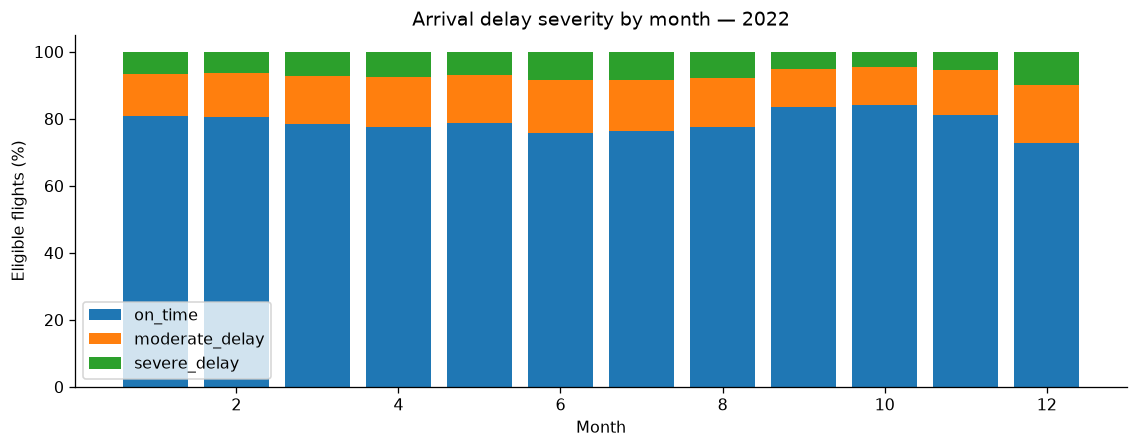

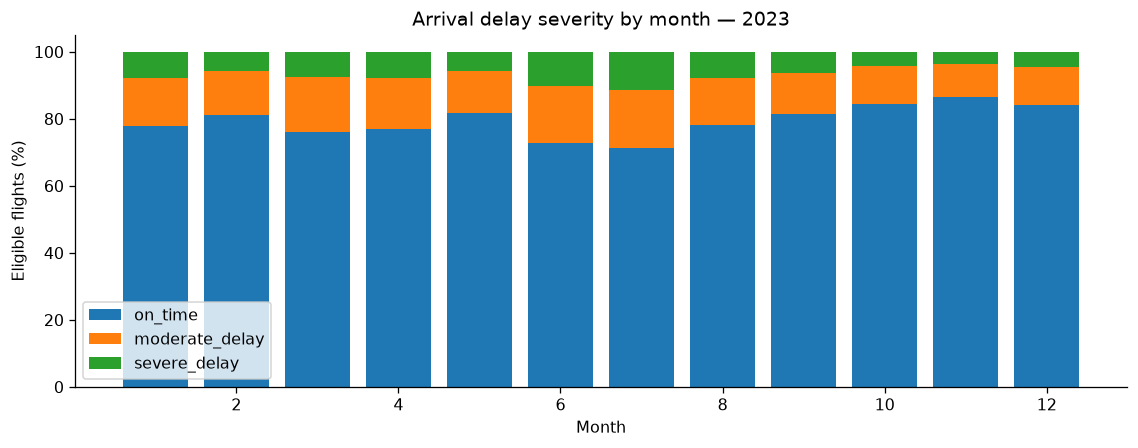

In [35]:
# Thresholds must match the project configuration.
# This notebook requires explicit values rather than silently choosing them.
import yaml
CONFIG_PATH = next((base / "configs" / "config.yaml" for base in
    (Path.cwd(), *Path.cwd().parents) if (base / "configs" / "config.yaml").is_file()), None)
if CONFIG_PATH is None:
    raise FileNotFoundError("Missing configs/config.yaml: define arrival-delay severity thresholds there.")
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = yaml.safe_load(f) or {}
# Support a clearly documented section; fail loudly if thresholds have not been approved.
severity_cfg = project_config.get("eda", {}).get("arrival_delay_thresholds_minutes", {})
if not {"moderate", "severe"} <= severity_cfg.keys():
    raise KeyError("Add eda.arrival_delay_thresholds_minutes.moderate and .severe to configs/config.yaml")
moderate_cutoff, severe_cutoff = float(severity_cfg["moderate"]), float(severity_cfg["severe"])
assert 0 < moderate_cutoff < severe_cutoff
severity = labelled_flights.with_columns(
    pl.when(pl.col("ARR_DELAY") < moderate_cutoff).then(pl.lit("on_time"))
    .when(pl.col("ARR_DELAY") < severe_cutoff).then(pl.lit("moderate_delay"))
    .otherwise(pl.lit("severe_delay")).alias("DELAY_SEVERITY")
)
severity_order = ["on_time", "moderate_delay", "severe_delay"]
severity_overall = (severity.group_by("DELAY_SEVERITY").agg(pl.len().alias("flights"))
    .with_columns((100 * pl.col("flights") / pl.col("flights").sum()).alias("pct"))
    .collect(engine="streaming"))
severity_month = (severity.group_by("YEAR", "MONTH", "DELAY_SEVERITY")
    .agg(pl.len().alias("flights")).collect(engine="streaming"))
severity_month = severity_month.with_columns(
    (100 * pl.col("flights") /
     pl.col("flights").sum().over("YEAR", "MONTH")).alias("pct"))
display(severity_overall.sort("DELAY_SEVERITY"))
display(severity_month.sort("YEAR", "MONTH", "DELAY_SEVERITY"))
for yr in [2022, 2023]:
    sub = severity_month.filter(pl.col("YEAR") == yr)
    months = range(1, 13)
    bottom = np.zeros(12)
    plt.figure(figsize=(10, 4))
    for label in severity_order:
        d = {int(row["MONTH"]): float(row["pct"])
             for row in sub.filter(pl.col("DELAY_SEVERITY") == label).iter_rows(named=True)}
        vals = np.array([d.get(m, 0) for m in months])
        plt.bar(months, vals, bottom=bottom, label=label)
        bottom += vals
    plt.title(f"Arrival delay severity by month — {yr}")
    plt.xlabel("Month"); plt.ylabel("Eligible flights (%)"); plt.legend()
    plt.tight_layout(); plt.show()


## 1.13 Statistical Associations

Correlations are descriptive and do not establish causal effects.

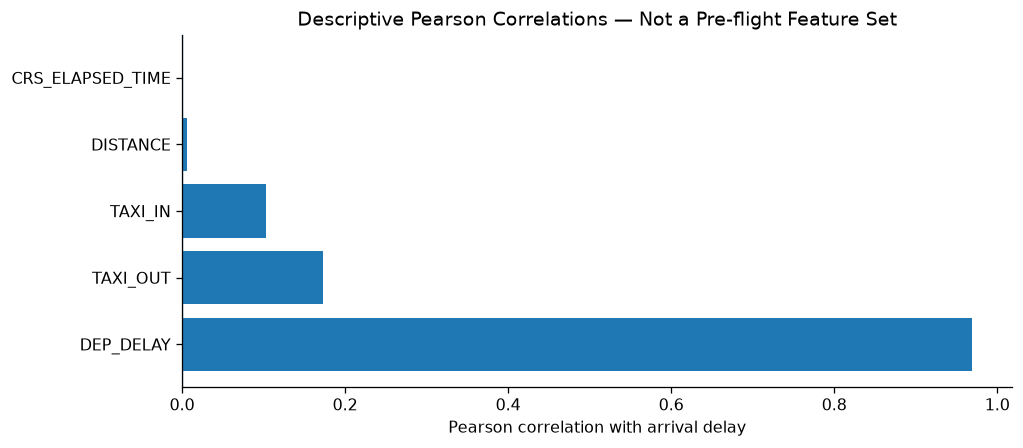

In [36]:
correlates = ["DEP_DELAY", "CRS_ELAPSED_TIME", "DISTANCE", "TAXI_OUT", "TAXI_IN"]
correlations = labelled_flights.select([
    pl.corr("ARR_DELAY", c).alias(c) for c in correlates
]).collect(engine="streaming")
corr_data = pl.DataFrame({
    "feature": correlates,
    "pearson_r_with_ARR_DELAY": [float(correlations[c][0]) if correlations[c][0] is not None else np.nan for c in correlates],
}).sort("pearson_r_with_ARR_DELAY", descending=True)

plt.figure(figsize=(9, 4))
plt.barh(corr_data["feature"].to_list(), corr_data["pearson_r_with_ARR_DELAY"].to_list())
plt.axvline(0, linewidth=.8)
plt.title("Descriptive Pearson Correlations — Not a Pre-flight Feature Set")
plt.xlabel("Pearson correlation with arrival delay")
plt.tight_layout()
plt.show()


## 1.14 Temporal Patterns

Compare delay rates by month, weekday and scheduled local departure hour.

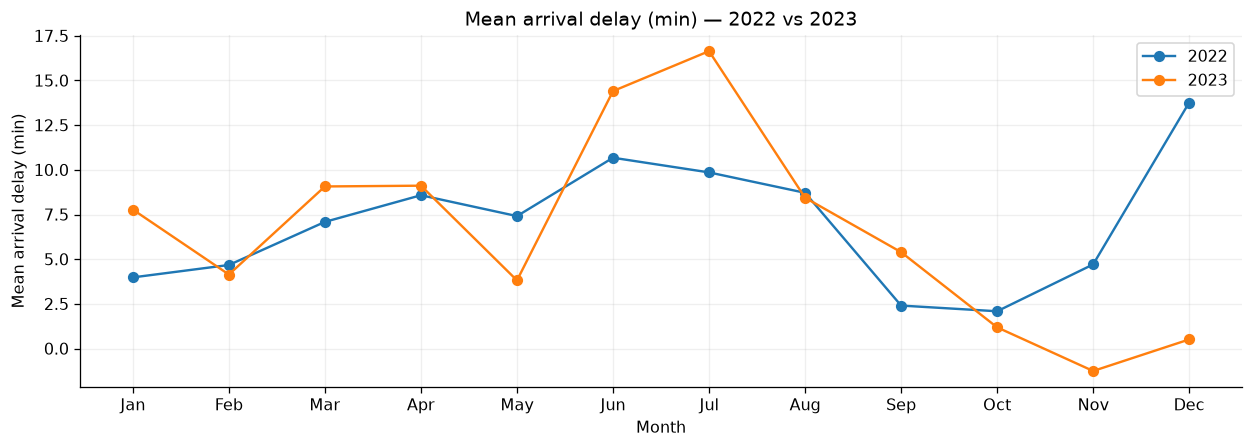

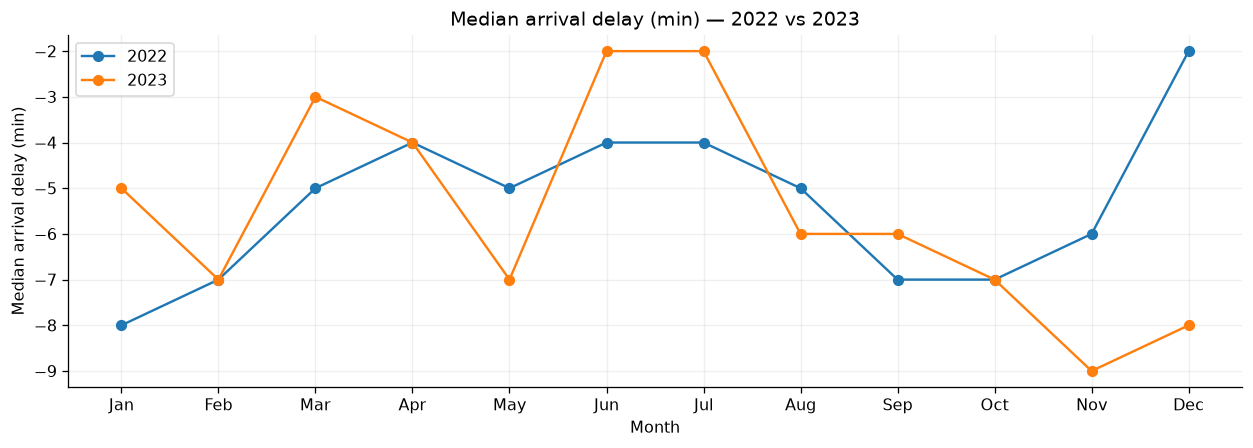

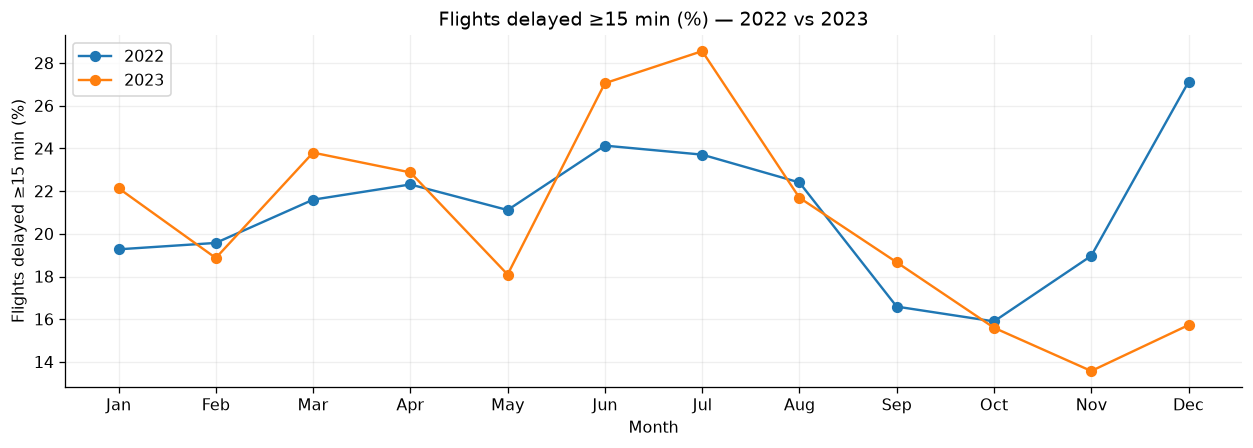

In [37]:
monthly_delays = (
    labelled_flights.group_by("YEAR", "MONTH")
    .agg(
        pl.len().alias("flights"),
        pl.col("ARR_DELAY").mean().alias("mean_delay"),
        pl.col("ARR_DELAY").median().alias("median_delay"),
        (pl.col("TARGET_DELAY_15").mean() * 100).alias("delay_rate"),
    )
    .sort("YEAR", "MONTH").collect(engine="streaming")
)

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
for metric, label in [("mean_delay", "Mean arrival delay (min)"),
                      ("median_delay", "Median arrival delay (min)"),
                      ("delay_rate", "Flights delayed ≥15 min (%)")]:
    plt.figure(figsize=(11, 4))
    for year in [2022, 2023]:
        v = monthly_delays.filter(pl.col("YEAR") == year).sort("MONTH")
        plt.plot(v["MONTH"].to_list(), v[metric].to_list(), marker="o", label=str(year))
    plt.xticks(range(1,13), month_labels)
    plt.xlabel("Month")
    plt.ylabel(label)
    plt.title(f"{label} — 2022 vs 2023")
    plt.legend()
    plt.grid(alpha=.2)
    plt.tight_layout()
    plt.show()


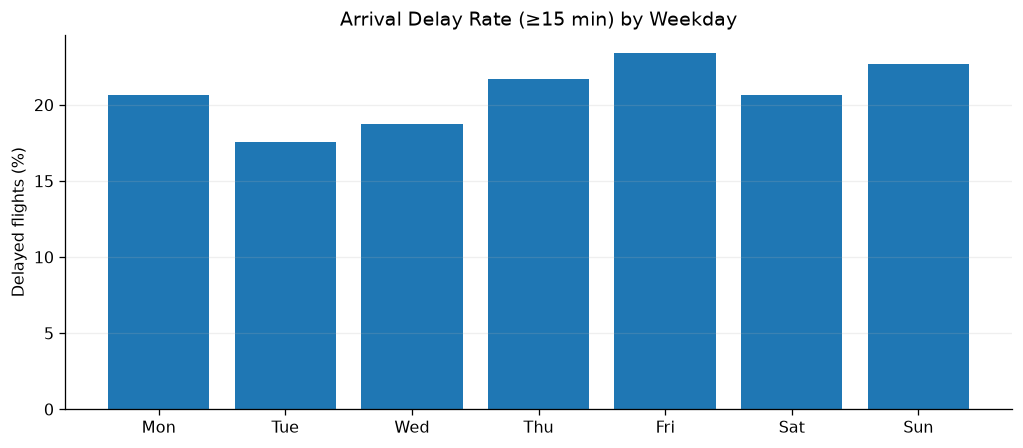

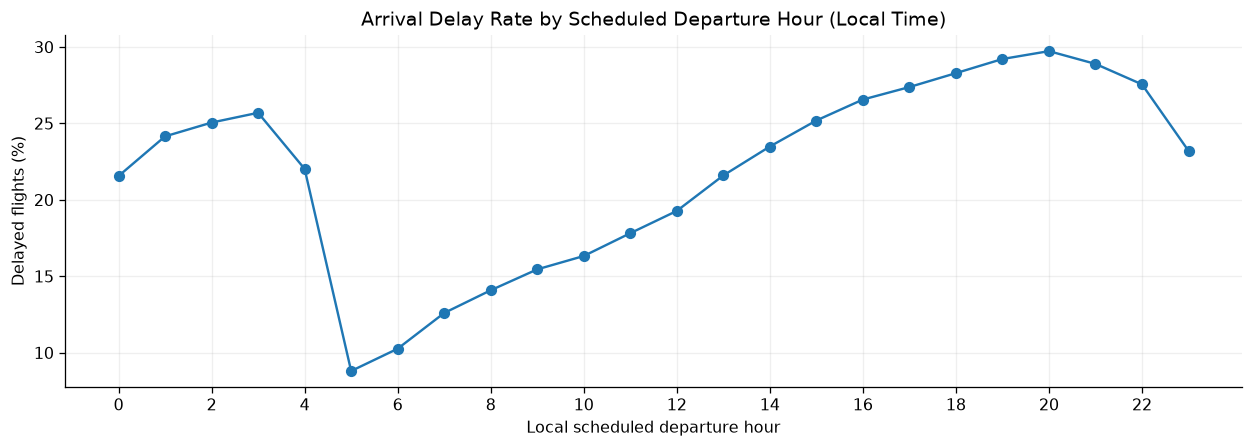

In [38]:
weekday_delay = (
    labelled_flights.group_by("DAY_OF_WEEK")
    .agg(pl.len().alias("flights"), (pl.col("TARGET_DELAY_15").mean() * 100).alias("delay_pct"))
    .sort("DAY_OF_WEEK").collect(engine="streaming")
)
plt.figure(figsize=(9, 4))
plt.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday_delay["delay_pct"].to_list())
plt.title("Arrival Delay Rate (≥15 min) by Weekday")
plt.ylabel("Delayed flights (%)")
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

hourly_delay = (
    labelled_flights.with_columns((pl.col("CRS_DEP_TIME") // 100).alias("local_dep_hour"))
    .filter(pl.col("local_dep_hour").is_between(0, 23))
    .group_by("local_dep_hour")
    .agg(pl.len().alias("flights"), (pl.col("TARGET_DELAY_15").mean() * 100).alias("delay_pct"))
    .sort("local_dep_hour").collect(engine="streaming")
)
plt.figure(figsize=(11, 4))
plt.plot(hourly_delay["local_dep_hour"].to_list(), hourly_delay["delay_pct"].to_list(), marker="o")
plt.title("Arrival Delay Rate by Scheduled Departure Hour (Local Time)")
plt.xlabel("Local scheduled departure hour")
plt.ylabel("Delayed flights (%)")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()


### Delay Severity by Scheduled Departure Period

Compare severity across weekdays and BTS scheduled-departure time blocks. When `DEP_TIME_BLK` is not in the input, construct equivalent bins from `CRS_DEP_TIME` without changing the raw data.

In [39]:
# The current LAIA Parquet schema does not include the original BTS DEP_TIME_BLK.
# Reconstruct its standard scheduled-departure bins from CRS_DEP_TIME for EDA.
if "DEP_TIME_BLK" in df.collect_schema():
    severity_with_block = severity
else:
    raw_time = pl.col("CRS_DEP_TIME")
    hour = (raw_time.cast(pl.Int32) // 100) % 24
    blocks = pl.when(raw_time.is_null()).then(pl.lit(None, dtype=pl.String))
    blocks = blocks.when((raw_time >= 0) & (raw_time <= 2400) &
                         (raw_time % 100 < 60) & (hour < 6)).then(pl.lit("0001-0559"))
    for h in range(6, 24):
        blocks = blocks.when((hour == h) & (raw_time % 100 < 60)).then(
            pl.lit(f"{h:02d}00-{h:02d}59"))
    blocks = blocks.otherwise(pl.lit(None, dtype=pl.String))
    severity_with_block = severity.with_columns(blocks.alias("DEP_TIME_BLK"))
    print("DEP_TIME_BLK reconstructed from CRS_DEP_TIME (not present in source Parquet).")
severity_blocks = (severity_with_block.filter(pl.col("DEP_TIME_BLK").is_not_null())
    .group_by("DEP_TIME_BLK", "DELAY_SEVERITY")
    .agg(pl.len().alias("flights")).collect(engine="streaming"))
severity_blocks = severity_blocks.with_columns(
    (100 * pl.col("flights") / pl.col("flights").sum().over("DEP_TIME_BLK")).alias("pct"))
display(severity_blocks.sort("DEP_TIME_BLK", "DELAY_SEVERITY"))
severity_weekdays = (severity.group_by("DAY_OF_WEEK", "DELAY_SEVERITY")
    .agg(pl.len().alias("flights")).collect(engine="streaming"))
severity_weekdays = severity_weekdays.with_columns(
    (100 * pl.col("flights") / pl.col("flights").sum().over("DAY_OF_WEEK")).alias("pct"))
display(severity_weekdays.sort("DAY_OF_WEEK", "DELAY_SEVERITY"))


DEP_TIME_BLK reconstructed from CRS_DEP_TIME (not present in source Parquet).


DEP_TIME_BLK,DELAY_SEVERITY,flights,pct
str,str,u32,f64
"""0001-0559""","""moderate_delay""",26355,6.646106
"""0001-0559""","""on_time""",356727,89.958088
"""0001-0559""","""severe_delay""",13466,3.395806
"""0600-0659""","""moderate_delay""",64922,6.856232
"""0600-0659""","""on_time""",849697,89.734134
…,…,…,…
"""2200-2259""","""on_time""",250392,72.443214
"""2200-2259""","""severe_delay""",31974,9.250692
"""2300-2359""","""moderate_delay""",17920,15.564338


DAY_OF_WEEK,DELAY_SEVERITY,flights,pct
i64,str,u32,f64
1,"""moderate_delay""",271644,13.808522
1,"""on_time""",1560749,79.337796
1,"""severe_delay""",134827,6.853682
2,"""moderate_delay""",223392,12.048983
2,"""on_time""",1528770,82.456506
…,…,…,…
6,"""on_time""",1364964,79.355465
6,"""severe_delay""",122910,7.145669
7,"""moderate_delay""",287898,14.890739


### 1.14.1 Scheduled vs Actual Flight Duration

Compare changes in scheduled and observed duration across the same directed route, airline and month. The implied buffer is `DEP_DELAY - ARR_DELAY`. These comparisons do not establish deliberate schedule padding.

In [40]:
duration_flights = (
    eligible.filter(
        pl.col("CRS_ELAPSED_TIME").is_not_null() &
        pl.col("DEP_DELAY").is_not_null() &
        (pl.col("CRS_ELAPSED_TIME") > 0)
    )
    .with_columns(
        (pl.col("CRS_ELAPSED_TIME") + pl.col("ARR_DELAY") - pl.col("DEP_DELAY"))
        .alias("actual_elapsed")
    )
    .filter(pl.col("actual_elapsed") > 0)
)
monthly_duration = (
    duration_flights.group_by("ORIGIN", "DEST", "OP_UNIQUE_CARRIER", "YEAR", "MONTH")
    .agg(
        pl.len().alias("n_flights"),
        pl.col("CRS_ELAPSED_TIME").mean().alias("scheduled"),
        pl.col("actual_elapsed").mean().alias("actual"),
    )
    .collect(engine="streaming")
)

matching_keys = ["ORIGIN", "DEST", "OP_UNIQUE_CARRIER", "MONTH"]
annual_months = {}
for year in (2022, 2023):
    annual_months[year] = monthly_duration.filter(
        (pl.col("YEAR") == year) & (pl.col("n_flights") >= 15)
    ).select(
        *matching_keys,
        pl.col("scheduled").alias(f"scheduled_{year}"),
        pl.col("actual").alias(f"actual_{year}"),
        pl.col("n_flights").alias(f"n_{year}"),
    )
matched = annual_months[2022].join(annual_months[2023], on=matching_keys, how="inner")

padding_changes = (
    matched.group_by("ORIGIN", "DEST", "OP_UNIQUE_CARRIER")
    .agg(
        pl.len().alias("matched_months"),
        pl.col("n_2022").sum().alias("flights_2022"),
        pl.col("n_2023").sum().alias("flights_2023"),
        (pl.col("scheduled_2023") - pl.col("scheduled_2022")).mean().alias("delta_scheduled"),
        (pl.col("actual_2023") - pl.col("actual_2022")).mean().alias("delta_actual"),
    )
    .filter(
        (pl.col("matched_months") >= 6) &
        (pl.col("flights_2022") >= 150) &
        (pl.col("flights_2023") >= 150)
    )
    .with_columns((pl.col("delta_scheduled") - pl.col("delta_actual")).alias("delta_buffer"))
)
print("Matched route–airline combinations:", padding_changes.height)


Matched route–airline combinations: 6388


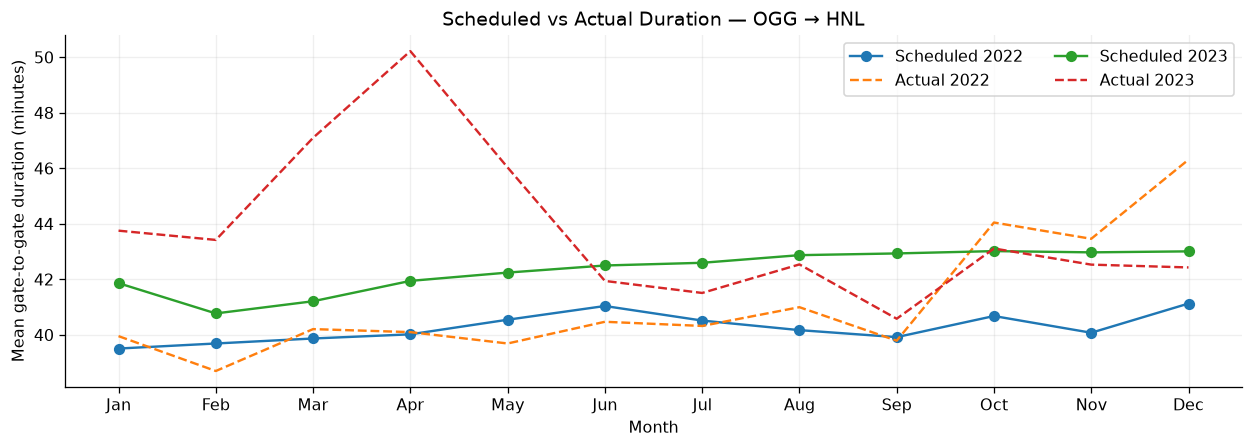

Note: this route can combine airlines and services; schedule changes are not established.


In [41]:
# Monthly pattern for the most frequent directed route.
example_route = route_counts.head(1)
route_origin = example_route["ORIGIN"][0]
route_dest = example_route["DEST"][0]
example_monthly = (
    duration_flights.filter(
        (pl.col("ORIGIN") == route_origin) & (pl.col("DEST") == route_dest)
    )
    .group_by("YEAR", "MONTH")
    .agg(
        pl.len().alias("flights"),
        pl.col("CRS_ELAPSED_TIME").mean().alias("scheduled"),
        pl.col("actual_elapsed").mean().alias("actual"),
    )
    .sort("YEAR", "MONTH")
    .collect(engine="streaming")
)
plt.figure(figsize=(11, 4))
for year in [2022, 2023]:
    v = example_monthly.filter(pl.col("YEAR") == year)
    plt.plot(v["MONTH"].to_list(), v["scheduled"].to_list(), marker="o", label=f"Scheduled {year}")
    plt.plot(v["MONTH"].to_list(), v["actual"].to_list(), linestyle="--", label=f"Actual {year}")
plt.xticks(range(1,13), month_labels)
plt.title(f"Scheduled vs Actual Duration — {route_origin} → {route_dest}")
plt.xlabel("Month")
plt.ylabel("Mean gate-to-gate duration (minutes)")
plt.legend(ncol=2)
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()
print("Note: this route can combine airlines and services; schedule changes are not established.")


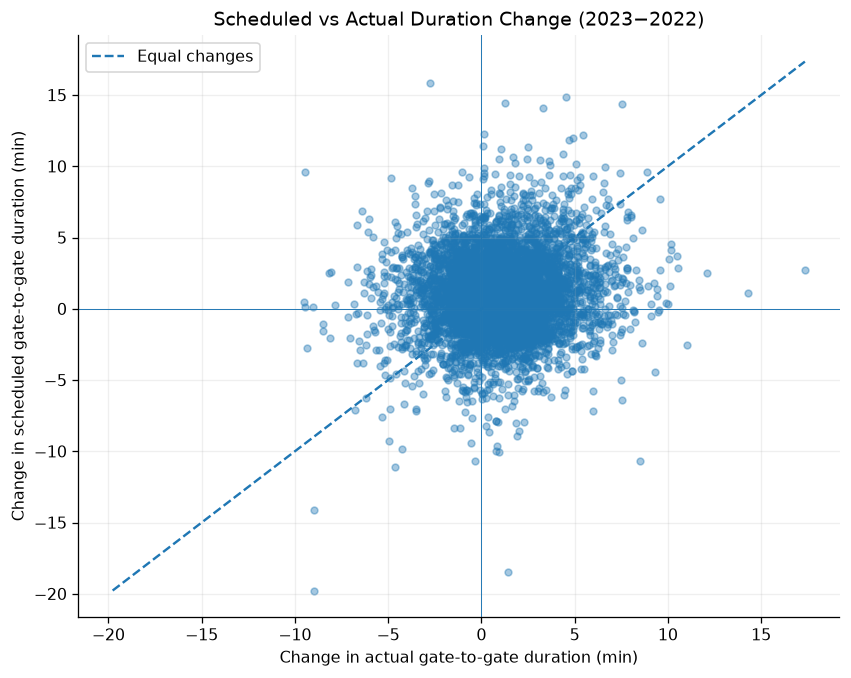

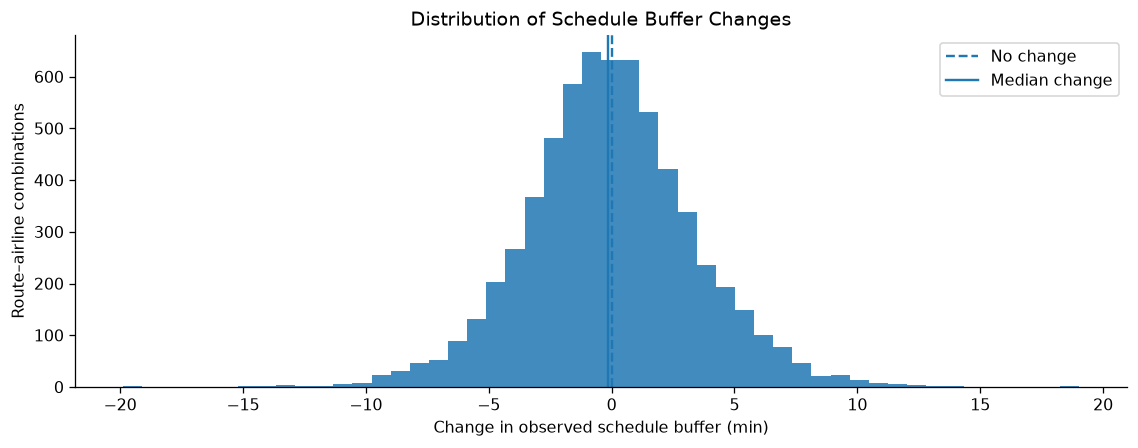

combinations,mean_delta_buffer,median_delta_buffer,pct_increased,pct_abs_change_ge_5min
u32,f64,f64,f64,f64
6388,-0.05,-0.14,48.3,13.7


Candidate pairs with ≥5-min scheduled AND buffer increase: 201


ORIGIN,DEST,OP_UNIQUE_CARRIER,matched_months,flights_2022,flights_2023,delta_scheduled,delta_actual,delta_buffer
str,str,str,u32,u32,u32,f64,f64,f64
"""LAX""","""EWR""","""NK""",7,205,389,9.564669,-9.463063,19.027733
"""DCA""","""HHH""","""YX""",6,202,188,15.878114,-2.738907,18.617021
"""JFK""","""DCA""","""YX""",12,2628,2286,9.160437,-4.83952,13.999957
"""LGA""","""RSW""","""B6""",12,476,572,6.889996,-6.38286,13.272855
"""ORH""","""LGA""","""9E""",12,285,289,14.428111,1.264063,13.164048
"""TTN""","""PBI""","""F9""",6,271,233,5.903644,-6.678071,12.581714
"""EYW""","""EWR""","""YX""",12,671,598,6.327372,-6.014671,12.342043
"""IAH""","""EWR""","""NK""",12,630,356,8.501784,-3.711074,12.212858
"""DCA""","""EYW""","""YX""",11,324,357,12.236833,0.136906,12.099927


In [42]:
if padding_changes.height:
    x = padding_changes["delta_actual"].to_numpy()
    y = padding_changes["delta_scheduled"].to_numpy()
    endpoints = [min(float(x.min()), float(y.min())), max(float(x.max()), float(y.max()))]
    plt.figure(figsize=(7.5, 6))
    plt.scatter(x, y, s=18, alpha=.4)
    plt.plot(endpoints, endpoints, "--", label="Equal changes")
    plt.axhline(0, linewidth=.6)
    plt.axvline(0, linewidth=.6)
    plt.xlabel("Change in actual gate-to-gate duration (min)")
    plt.ylabel("Change in scheduled gate-to-gate duration (min)")
    plt.title("Scheduled vs Actual Duration Change (2023−2022)")
    plt.legend()
    plt.grid(alpha=.2)
    plt.tight_layout()
    plt.show()

    buffers = padding_changes["delta_buffer"].to_numpy()
    plt.figure(figsize=(10, 4))
    plt.hist(buffers, bins=50, alpha=.85)
    plt.axvline(0, linestyle="--", label="No change")
    plt.axvline(float(padding_changes["delta_buffer"].median()), label="Median change")
    plt.xlabel("Change in observed schedule buffer (min)")
    plt.ylabel("Route–airline combinations")
    plt.title("Distribution of Schedule Buffer Changes")
    plt.legend()
    plt.tight_layout()
    plt.show()

    display(padding_changes.select(
        pl.len().alias("combinations"),
        pl.col("delta_buffer").mean().round(2).alias("mean_delta_buffer"),
        pl.col("delta_buffer").median().round(2).alias("median_delta_buffer"),
        (pl.col("delta_buffer").gt(0).mean() * 100).round(1).alias("pct_increased"),
        (pl.col("delta_buffer").abs().ge(5).mean() * 100).round(1).alias("pct_abs_change_ge_5min"),
    ))
    candidates = padding_changes.filter(
        (pl.col("delta_scheduled") >= 5) & (pl.col("delta_buffer") >= 5)
    ).sort("delta_buffer", descending=True)
    print("Candidate pairs with ≥5-min scheduled AND buffer increase:", candidates.height)
    display(candidates.head(10))
else:
    print("No eligible matched pairs with the current thresholds. Review thresholds.")


## 1.15 Differences Across Airports, Routes and Aircraft

Report group sizes alongside delay rates; small groups can be unstable.

In [43]:
origin_delay = (
    labelled_flights.group_by("ORIGIN")
    .agg(
        pl.len().alias("flights"),
        pl.col("ARR_DELAY").mean().alias("mean_arrival_delay"),
        (pl.col("TARGET_DELAY_15").mean() * 100).alias("delay_rate"),
    )
    .filter(pl.col("flights") >= 500)
    .collect(engine="streaming")
)
route_delay = (
    labelled_flights.group_by("ORIGIN", "DEST")
    .agg(pl.len().alias("flights"),
         (pl.col("TARGET_DELAY_15").mean() * 100).alias("delay_rate"))
    .filter(pl.col("flights") >= 200)
    .collect(engine="streaming")
)
airline_delay = (
    labelled_flights.group_by("OP_UNIQUE_CARRIER")
    .agg(pl.len().alias("flights"),
         (pl.col("TARGET_DELAY_15").mean() * 100).alias("delay_rate"))
    .collect(engine="streaming")
)
aircraft_delay = (
    labelled_flights.filter(pl.col("TAIL_NUM").is_not_null() & (pl.col("TAIL_NUM") != ""))
    .group_by("TAIL_NUM")
    .agg(pl.len().alias("flights"),
         (pl.col("TARGET_DELAY_15").mean() * 100).alias("delay_rate"))
    .filter(pl.col("flights") >= 100)
    .collect(engine="streaming")
)
print("Origin airports with ≥500 eligible flights:", origin_delay.height)
print("Routes with ≥200 eligible flights:", route_delay.height)
print("Aircraft with ≥100 eligible flights:", aircraft_delay.height)


Origin airports with ≥500 eligible flights: 346
Routes with ≥200 eligible flights: 5420
Aircraft with ≥100 eligible flights: 6197


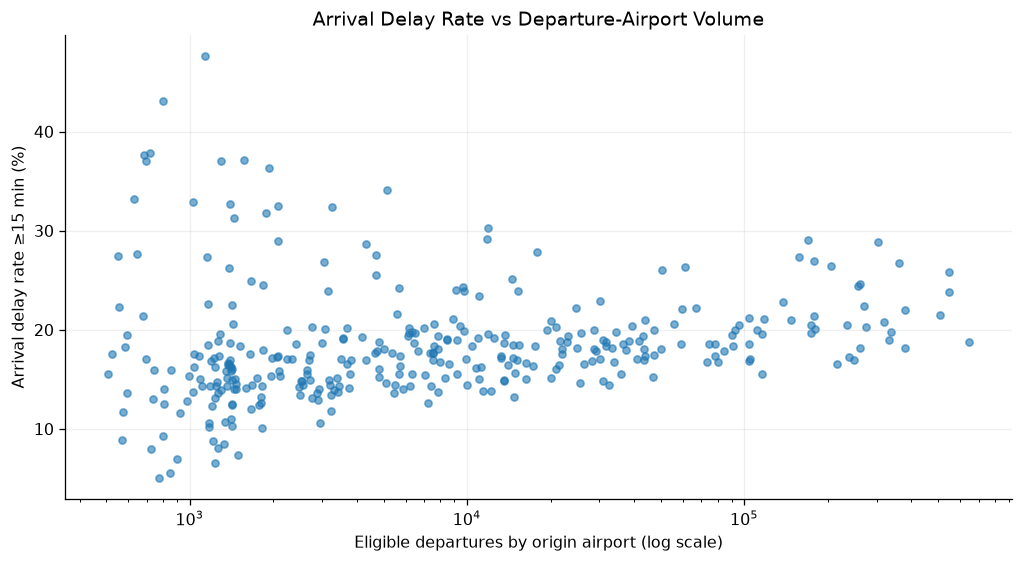

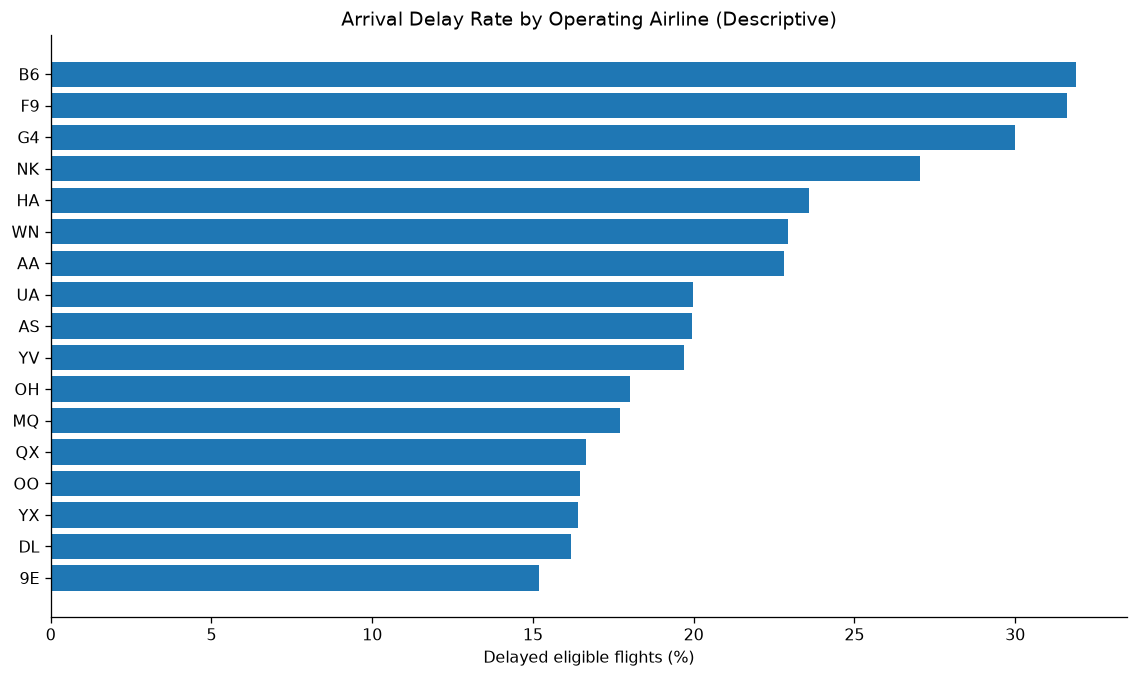

In [44]:
plt.figure(figsize=(9, 5))
plt.scatter(origin_delay["flights"].to_numpy(), origin_delay["delay_rate"].to_numpy(), alpha=.6, s=20)
plt.xscale("log")
plt.title("Arrival Delay Rate vs Departure-Airport Volume")
plt.xlabel("Eligible departures by origin airport (log scale)")
plt.ylabel("Arrival delay rate ≥15 min (%)")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

carrier_rates = airline_delay.sort("delay_rate")
plt.figure(figsize=(10, 6))
plt.barh(carrier_rates["OP_UNIQUE_CARRIER"].to_list(), carrier_rates["delay_rate"].to_list())
plt.title("Arrival Delay Rate by Operating Airline (Descriptive)")
plt.xlabel("Delayed eligible flights (%)")
plt.tight_layout()
plt.show()


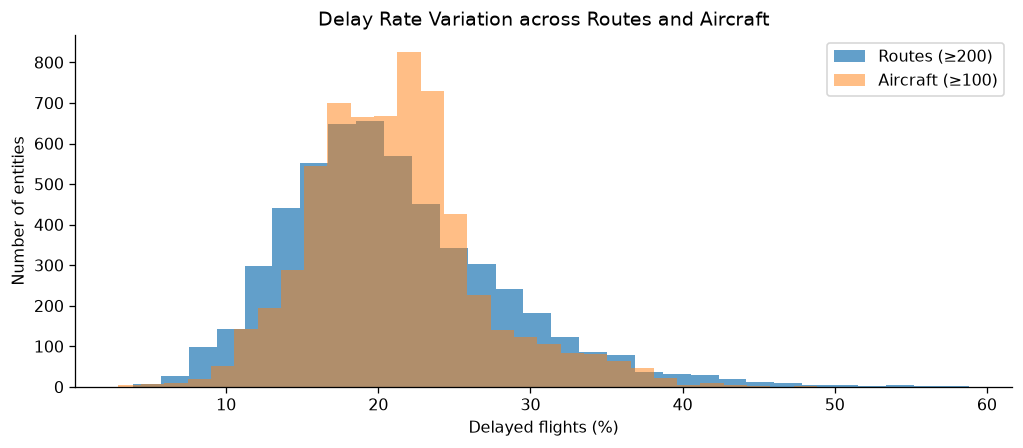

In [45]:
# Rate distributions depend on the minimum group size.
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(route_delay["delay_rate"].to_numpy(), bins=30, alpha=.7, label="Routes (≥200)")
ax.hist(aircraft_delay["delay_rate"].to_numpy(), bins=30, alpha=.5, label="Aircraft (≥100)")
ax.set(title="Delay Rate Variation across Routes and Aircraft", xlabel="Delayed flights (%)",
       ylabel="Number of entities")
ax.legend()
plt.tight_layout()
plt.show()

# Account for seasonality and airline mix when comparing groups,
# uncertainty intervals and stability; these are not causal rankings.


## 1.16 Airport Network Structure

An airport is a node and a directed route is an edge weighted by reported flights. Connectivity metrics describe network structure, not delay propagation. Aircraft rotations require validated timestamps and continuity checks.

airport_nodes,directed_route_edges,directed_routes_with_reverse,routes_in_both_2022_2023,max_out_degree,max_in_degree,median_out_degree,median_in_degree
i64,i64,i64,i64,i64,i64,f64,f64
373,7163,7122,6305,193,192,6.0,6.0


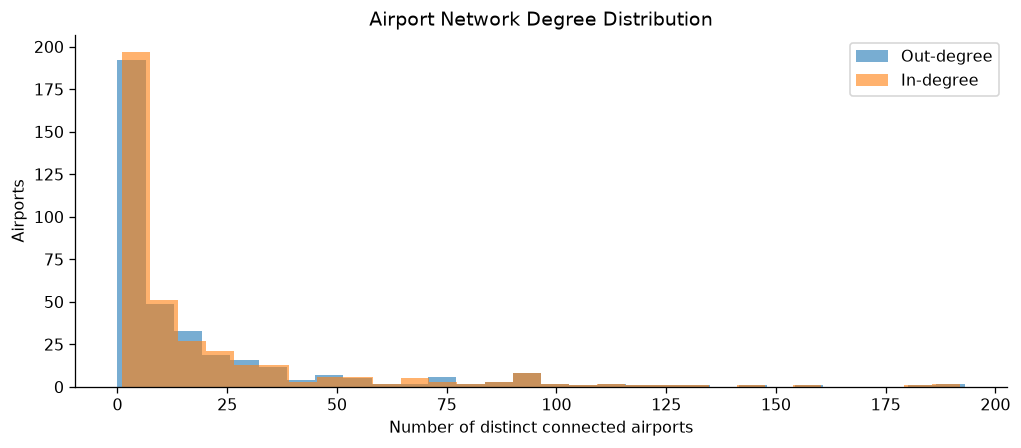

In [46]:
# Summary of observed airport connectivity.
network_summary = {
    "airport_nodes": airport_counts.height,
    "directed_route_edges": route_counts.height,
    "directed_routes_with_reverse": reciprocal,
    "routes_in_both_2022_2023": len(shared),
    "max_out_degree": int(airport_degree["out_degree"].max()),
    "max_in_degree": int(airport_degree["in_degree"].max()),
    "median_out_degree": float(airport_degree["out_degree"].median()),
    "median_in_degree": float(airport_degree["in_degree"].median()),
}
display(pl.DataFrame([network_summary]))

plt.figure(figsize=(9, 4))
plt.hist(airport_degree["out_degree"].to_numpy(), bins=30, alpha=.6, label="Out-degree")
plt.hist(airport_degree["in_degree"].to_numpy(), bins=30, alpha=.6, label="In-degree")
plt.title("Airport Network Degree Distribution")
plt.xlabel("Number of distinct connected airports")
plt.ylabel("Airports")
plt.legend()
plt.tight_layout()
plt.show()


### Aircraft Rotation Limitations

Reliable flight chains require UTC timestamps, airport continuity and plausible turnaround times.

## 1.17 Key Findings and Limitations

Earlier notebook counts: 13,577,024 records, 43 attributes, 730 dates, 373 airports, 7,163 directed routes, 17 airlines and approximately 6,361 identified aircraft. Recheck these figures after running the notebook.

Temporal and airport-level patterns vary; associations do not establish causality. Local timestamps, eligibility criteria, missing data and small groups limit interpretation.

In [47]:
# Check aggregated counts without changing raw data.
print("Raw flights:", int(overview["flights"][0]))
print("Monthly coverage periods:", monthly_flights.height)
print("Daily dates:", daily_flights.height)
print("Airport nodes:", airport_counts.height)
print("Directed routes:", route_counts.height)
print("Operating airlines:", airline_counts.height)
print("Known aircraft IDs:", aircraft_counts.height)
print("Eligible arrival-delay flights:", int(target_summary["eligible_flights"][0]))
print("Missing expected columns:", len(missing_columns))
print("Type-family findings:", len(type_findings))
print("Potential repeated candidate-key excess (hash-based):", candidate_duplicate_excess)
print("Open: 1.10 Prediction Context — needs professor decision")


Raw flights: 13577024
Monthly coverage periods: 24
Daily dates: 730
Airport nodes: 373
Directed routes: 7163
Operating airlines: 17
Known aircraft IDs: 6360
Eligible arrival-delay flights: 13275415
Missing expected columns: 0
Type-family findings: 0
Potential repeated candidate-key excess (hash-based): 0
Open: 1.10 Prediction Context — needs professor decision


## 1.18 Arrival Traffic and Delays

Compare observed delay rates across scheduled-arrival volume and relative pressure at destination airports. Rates exclude cancelled/diverted flights; traffic includes scheduled flights. Hours are local, and `FL_DATE` may not equal the actual local arrival date for overnight flights. Results are descriptive, not causal.

In [48]:
# Scheduled arrival counts grouped by destination airport,
# flight date and local scheduled arrival hour (not validated UTC time).
arrivals_hourly = (
    df.filter(
        pl.col("DEST").is_not_null()
        & pl.col("CRS_ARR_TIME").is_not_null()
        & pl.col("FL_DATE").is_not_null()
    )
    .with_columns(
        (pl.col("CRS_ARR_TIME").cast(pl.Int32) // 100).alias("arrival_hour"),
    )
    .filter(pl.col("arrival_hour").is_between(0, 23))
    .group_by("DEST", "FL_DATE", "DAY_OF_WEEK", "arrival_hour")
    .agg(
        pl.len().alias("scheduled_arrivals"),
        ((pl.col("CANCELLED") == 0)
         & (pl.col("DIVERTED") == 0)
         & pl.col("ARR_DELAY").is_not_null()).sum().alias("eligible_arrivals"),
        (((pl.col("CANCELLED") == 0)
          & (pl.col("DIVERTED") == 0)
          & (pl.col("ARR_DELAY") >= 15)).sum()).alias("delayed_arrivals"),
    )
    .collect(engine="streaming")
)
arrivals_hourly = arrivals_hourly.with_columns(
    pl.when(pl.col("eligible_arrivals") > 0)
      .then(pl.col("delayed_arrivals") / pl.col("eligible_arrivals"))
      .otherwise(None).alias("delay_rate"),
    (pl.col("eligible_arrivals") / pl.col("scheduled_arrivals")).alias("coverage"),
)
print("Airport-date-hour observations:", arrivals_hourly.height)
print("Scheduled arrivals:", int(arrivals_hourly["scheduled_arrivals"].sum()))
print("Eligible arrivals:", int(arrivals_hourly["eligible_arrivals"].sum()))
display(arrivals_hourly.head(8))


Airport-date-hour observations: 2131384
Scheduled arrivals: 13577018
Eligible arrivals: 13275409


DEST,FL_DATE,DAY_OF_WEEK,arrival_hour,scheduled_arrivals,eligible_arrivals,delayed_arrivals,delay_rate,coverage
str,datetime[ns],i64,i32,u32,u32,u32,f64,f64
"""LAX""",2022-03-07 00:00:00,1,19,22,22,3,0.136364,1.0
"""BDL""",2022-03-12 00:00:00,6,0,8,8,7,0.875,1.0
"""RDU""",2022-03-28 00:00:00,1,22,11,11,3,0.272727,1.0
"""STX""",2022-03-18 00:00:00,5,14,1,1,1,1.0,1.0
"""DFW""",2022-03-20 00:00:00,7,13,54,54,5,0.092593,1.0
"""PHX""",2022-03-03 00:00:00,4,12,40,39,4,0.102564,0.975
"""BNA""",2022-03-06 00:00:00,7,16,19,19,4,0.210526,1.0
"""LGA""",2022-03-22 00:00:00,2,22,19,19,7,0.368421,1.0


pressure_group,airport_hour_windows,eligible_flights,delayed_flights,avg_scheduled_arrivals,delay_pct
str,u32,u32,u32,f64,f64
"""<0.75×""",55876,518615,105069,9.460412,20.259537
"""0.75–1×""",230804,3692805,746804,16.328079,20.223218
"""1–1.25×""",256670,4765807,992668,18.942151,20.828959
"""1.25–1.5×""",97336,1277133,283823,13.361942,22.223449
"""≥1.5×""",58045,550036,127539,9.647032,23.187391


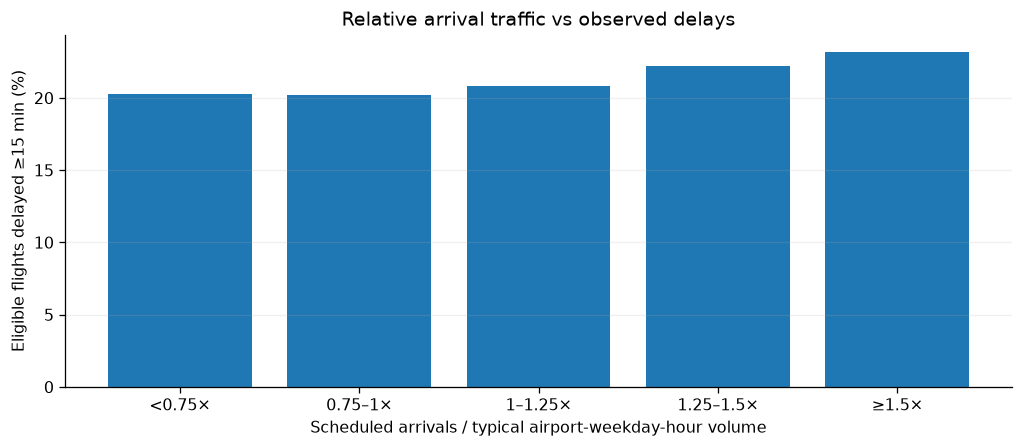

In [49]:
# Typical volume by airport, weekday and local hour.
# Descriptive historical average; not an as-of-time predictor
# Historical reference is descriptive and includes the full period.
reference = (
    arrivals_hourly.group_by("DEST", "DAY_OF_WEEK", "arrival_hour")
    .agg(
        pl.col("scheduled_arrivals").mean().alias("typical_arrivals"),
        pl.len().alias("observed_windows"),
    )
)
arrival_pressure = (
    arrivals_hourly.join(reference, on=["DEST", "DAY_OF_WEEK", "arrival_hour"], how="left")
    .with_columns(
        (pl.col("scheduled_arrivals") / pl.col("typical_arrivals"))
          .alias("relative_pressure")
    )
    .filter(
        (pl.col("eligible_arrivals") >= 5)
        & (pl.col("observed_windows") >= 10)
        & pl.col("relative_pressure").is_finite()
    )
)
# Relative-traffic bins, including unusually busy windows.
arrival_pressure = arrival_pressure.with_columns(
    pl.when(pl.col("relative_pressure") < 0.75).then(pl.lit("<0.75×"))
    .when(pl.col("relative_pressure") < 1.0).then(pl.lit("0.75–1×"))
    .when(pl.col("relative_pressure") < 1.25).then(pl.lit("1–1.25×"))
    .when(pl.col("relative_pressure") < 1.5).then(pl.lit("1.25–1.5×"))
    .otherwise(pl.lit("≥1.5×")).alias("pressure_group")
)
pressure_summary = (
    arrival_pressure.group_by("pressure_group")
    .agg(
        pl.len().alias("airport_hour_windows"),
        pl.col("eligible_arrivals").sum().alias("eligible_flights"),
        pl.col("delayed_arrivals").sum().alias("delayed_flights"),
        pl.col("scheduled_arrivals").mean().alias("avg_scheduled_arrivals"),
    )
    .with_columns((100 * pl.col("delayed_flights") / pl.col("eligible_flights")).alias("delay_pct"))
)
order = ["<0.75×", "0.75–1×", "1–1.25×", "1.25–1.5×", "≥1.5×"]
pressure_summary = pressure_summary.with_columns(
    pl.col("pressure_group").replace_strict({s: i for i,s in enumerate(order)}).alias("_order")
).sort("_order").drop("_order")
display(pressure_summary)
plt.figure(figsize=(9, 4))
plt.bar(pressure_summary["pressure_group"].to_list(), pressure_summary["delay_pct"].to_list())
plt.xlabel("Scheduled arrivals / typical airport-weekday-hour volume")
plt.ylabel("Eligible flights delayed ≥15 min (%)")
plt.title("Relative arrival traffic vs observed delays")
plt.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()


In [50]:
# Sensitivity check: exclude scheduled arrivals from 00:00 to 05:59,
# when FL_DATE is particularly unreliable as the arrival calendar date.
daytime = arrival_pressure.filter(pl.col("arrival_hour").is_between(6, 23))
day_summary = (
    daytime.group_by("pressure_group")
    .agg(pl.col("eligible_arrivals").sum().alias("n"),
         pl.col("delayed_arrivals").sum().alias("delayed"))
    .with_columns((100 * pl.col("delayed") / pl.col("n")).alias("delay_pct"))
    .sort("pressure_group")
)
print("Sensitivity check — scheduled arrivals from 06:00 to 23:00:")
display(day_summary)
print("Note: this restriction does not correct all local arrival-date ambiguities.")


Sensitivity check — scheduled arrivals from 06:00 to 23:00:


pressure_group,n,delayed,delay_pct
str,u32,u32,f64
"""0.75–1×""",3654579,736133,20.142758
"""1.25–1.5×""",1232494,269820,21.892196
"""1–1.25×""",4711268,976189,20.720303
"""<0.75×""",507042,102055,20.127524
"""≥1.5×""",508456,113153,22.254236


Note: this restriction does not correct all local arrival-date ambiguities.


### Findings

Complete after executing the analysis:
- Arrival volume versus observed delay rate.
- Relative arrival pressure versus delay rate, with group sample sizes.
- Sensitivity to excluding overnight hours.

These are observational associations, not causal estimates.

## 1.19 Categorical Frequencies and New Categories

For `OP_UNIQUE_CARRIER`, `ORIGIN` and `DEST`, examine unique values, frequencies, rare categories, and categories in 2023 absent from 2022. The rarity threshold is specified in the project configuration.

In [52]:
rarity_cfg = project_config["eda"]["rarity"]

rare_min = rarity_cfg["min_count"]
rare_share = rarity_cfg["min_share"]

category_results = {}

for field in ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST"]:
    counts = (
        df.group_by(field)
        .agg(
            pl.len().alias("flights"),
            (pl.col("YEAR") == 2022).sum().alias("flights_2022"),
            (pl.col("YEAR") == 2023).sum().alias("flights_2023"),
        )
        .sort("flights", descending=True)
        .collect(engine="streaming")
    )

    total = counts["flights"].sum()

    counts = counts.with_columns(
        (pl.col("flights") / total).alias("share")
    ).with_columns(
        (
            (pl.col("flights") < rare_min)
            | (pl.col("share") < rare_share)
        ).alias("rare"),
        (
            (pl.col("flights_2022") == 0)
            & (pl.col("flights_2023") > 0)
        ).alias("new_in_2023"),
    )

    category_results[field] = counts

    print(
        f"{field}: {counts.height} categories; "
        f"{counts['rare'].sum()} rare; "
        f"{counts['new_in_2023'].sum()} new in 2023"
    )

    display(counts.head(15))
    display(counts.filter(pl.col("new_in_2023")))
    display(counts.filter(pl.col("rare")).head(15))

OP_UNIQUE_CARRIER: 17 categories; 0 rare; 0 new in 2023


OP_UNIQUE_CARRIER,flights,flights_2022,flights_2023,share,rare,new_in_2023
str,u32,u32,u32,f64,bool,bool
"""WN""",2745614,1307149,1438465,0.202225,false,false
"""DL""",1878158,893172,984986,0.138334,false,false
"""AA""",1814676,874145,940531,0.133658,false,false
"""OO""",1408739,733576,675163,0.103759,false,false
"""UA""",1358685,626473,732212,0.100072,false,false
…,…,…,…,…,…,…
"""9E""",433461,231941,201520,0.031926,false,false
"""OH""",408594,214450,194144,0.030095,false,false
"""F9""",333024,155482,177542,0.024528,false,false


OP_UNIQUE_CARRIER,flights,flights_2022,flights_2023,share,rare,new_in_2023
str,u32,u32,u32,f64,bool,bool


OP_UNIQUE_CARRIER,flights,flights_2022,flights_2023,share,rare,new_in_2023
str,u32,u32,u32,f64,bool,bool


ORIGIN: 372 categories; 254 rare; 0 new in 2023


ORIGIN,flights,flights_2022,flights_2023,share,rare,new_in_2023
str,u32,u32,u32,f64,bool,bool
"""ATL""",654389,317926,336463,0.048198,false,false
"""DFW""",561952,276708,285244,0.04139,false,false
"""DEN""",560452,271467,288985,0.041279,false,false
"""ORD""",519438,260571,258867,0.038259,false,false
"""CLT""",386882,191782,195100,0.028495,false,false
…,…,…,…,…,…,…
"""MCO""",311127,146758,164369,0.022916,false,false
"""DCA""",282307,142302,140005,0.020793,false,false
"""BOS""",276993,136476,140517,0.020402,false,false


... (2 outputs left out)

DEST: 373 categories; 255 rare; 0 new in 2023


DEST,flights,flights_2022,flights_2023,share,rare,new_in_2023
str,u32,u32,u32,f64,bool,bool
"""ATL""",654368,317910,336458,0.048197,false,false
"""DFW""",561929,276711,285218,0.041388,false,false
"""DEN""",560431,271459,288972,0.041278,false,false
"""ORD""",519430,260587,258843,0.038258,false,false
"""CLT""",386901,191795,195106,0.028497,false,false
…,…,…,…,…,…,…
"""MCO""",311156,146784,164372,0.022918,false,false
"""DCA""",282330,142320,140010,0.020795,false,false
"""BOS""",277002,136479,140523,0.020402,false,false


DEST,flights,flights_2022,flights_2023,share,rare,new_in_2023
str,u32,u32,u32,f64,bool,bool


DEST,flights,flights_2022,flights_2023,share,rare,new_in_2023
str,u32,u32,u32,f64,bool,bool
"""ECP""",13430,6708,6722,0.000989,true,false
"""ITO""",13388,6164,7224,0.000986,true,false
"""ASE""",13055,6464,6591,0.000962,true,false
"""MHT""",12977,6704,6273,0.000956,true,false
"""MFR""",12373,7664,4709,0.000911,true,false
…,…,…,…,…,…,…
"""SBN""",11198,5378,5820,0.000825,true,false
"""PSC""",11164,5797,5367,0.000822,true,false
"""CHA""",10918,5090,5828,0.000804,true,false


## 1.20 Year-to-Year Distribution Comparison

Compare 2022 and 2023 for monthly delay severity, selected numeric distributions and categorical frequencies. These are descriptive shifts, not formal proof of drift.

In [53]:
numeric_fields = [c for c in ["CRS_ELAPSED_TIME", "DISTANCE", "CRS_DEP_TIME"]
                  if c in df.collect_schema()]
year_numeric = (df.group_by("YEAR").agg(
    pl.len().alias("flights"),
    *[pl.col(c).median().alias(f"{c}_median") for c in numeric_fields],
    *[pl.col(c).quantile(0.25).alias(f"{c}_q25") for c in numeric_fields],
    *[pl.col(c).quantile(0.75).alias(f"{c}_q75") for c in numeric_fields]
).sort("YEAR").collect(engine="streaming"))
display(year_numeric)
for field, counts in category_results.items():
    total22 = counts["flights_2022"].sum(); total23 = counts["flights_2023"].sum()
    shift = counts.with_columns(
        (pl.col("flights_2022") / total22).alias("share_2022"),
        (pl.col("flights_2023") / total23).alias("share_2023"))
    shift = shift.with_columns((pl.col("share_2023") - pl.col("share_2022")).alias("share_delta"))
    print(f"Largest category-share changes: {field}")
    display(shift.with_columns(pl.col("share_delta").abs().alias("abs_change"))
            .sort("abs_change", descending=True).head(10).drop("abs_change"))


YEAR,flights,CRS_ELAPSED_TIME_median,DISTANCE_median,CRS_DEP_TIME_median,CRS_ELAPSED_TIME_q25,DISTANCE_q25,CRS_DEP_TIME_q25,CRS_ELAPSED_TIME_q75,DISTANCE_q75,CRS_DEP_TIME_q75
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
2022,6729125,126.0,666.0,1320.0,90.0,386.0,910.0,174.0,1050.0,1735.0
2023,6847899,129.0,679.0,1324.0,92.0,399.0,910.0,176.0,1067.0,1741.0


Largest category-share changes: OP_UNIQUE_CARRIER


OP_UNIQUE_CARRIER,flights,flights_2022,flights_2023,share,rare,new_in_2023,share_2022,share_2023,share_delta
str,u32,u32,u32,f64,bool,bool,f64,f64,f64
"""YV""",114779,114779,0,0.008454,false,false,0.017057,0.0,-0.017057
"""WN""",2745614,1307149,1438465,0.202225,false,false,0.194252,0.210059,0.015807
"""UA""",1358685,626473,732212,0.100072,false,false,0.093099,0.106925,0.013826
"""QX""",88791,88791,0,0.00654,false,false,0.013195,0.0,-0.013195
"""DL""",1878158,893172,984986,0.138334,false,false,0.132732,0.143838,0.011105
"""OO""",1408739,733576,675163,0.103759,false,false,0.109015,0.098594,-0.010421
"""AA""",1814676,874145,940531,0.133658,false,false,0.129905,0.137346,0.007441
"""9E""",433461,231941,201520,0.031926,false,false,0.034468,0.029428,-0.00504
"""NK""",496271,232400,263871,0.036552,false,false,0.034536,0.038533,0.003997


Largest category-share changes: ORIGIN


ORIGIN,flights,flights_2022,flights_2023,share,rare,new_in_2023,share_2022,share_2023,share_delta
str,u32,u32,u32,f64,bool,bool,f64,f64,f64
"""IAH""",237763,125871,111892,0.017512,false,false,0.018705,0.01634,-0.002366
"""MCO""",311127,146758,164369,0.022916,false,false,0.021809,0.024003,0.002193
"""SEA""",337821,174009,163812,0.024882,false,false,0.025859,0.023921,-0.001938
"""ATL""",654389,317926,336463,0.048198,false,false,0.047246,0.049134,0.001887
"""DEN""",560452,271467,288985,0.041279,false,false,0.040342,0.042201,0.001858
"""LAS""",366380,175503,190877,0.026985,false,false,0.026081,0.027874,0.001793
"""LGA""",333142,169416,163726,0.024537,false,false,0.025177,0.023909,-0.001268
"""PHX""",341910,165219,176691,0.025183,false,false,0.024553,0.025802,0.001249
"""BWI""",182830,86559,96271,0.013466,false,false,0.012863,0.014058,0.001195


Largest category-share changes: DEST


DEST,flights,flights_2022,flights_2023,share,rare,new_in_2023,share_2022,share_2023,share_delta
str,u32,u32,u32,f64,bool,bool,f64,f64,f64
"""IAH""",237743,125844,111899,0.017511,false,false,0.018701,0.016341,-0.002361
"""MCO""",311156,146784,164372,0.022918,false,false,0.021813,0.024003,0.00219
"""SEA""",337793,174007,163786,0.02488,false,false,0.025859,0.023918,-0.001941
"""ATL""",654368,317910,336458,0.048197,false,false,0.047244,0.049133,0.001889
"""DEN""",560431,271459,288972,0.041278,false,false,0.040341,0.042199,0.001858
"""LAS""",366398,175519,190879,0.026987,false,false,0.026083,0.027874,0.001791
"""LGA""",333132,169414,163718,0.024536,false,false,0.025176,0.023908,-0.001268
"""PHX""",341901,165218,176683,0.025182,false,false,0.024553,0.025801,0.001248
"""BWI""",182831,86572,96259,0.013466,false,false,0.012865,0.014057,0.001191


## 1.21 Reference Statistics for Monitoring

Export frequency and numeric distribution references **from the approved training period only**. `configs/config.yaml` must specify `eda.train_end_date` (`YYYY-MM-DD`); this notebook does not infer split dates.

In [55]:
from datetime import date
from pathlib import Path
import json
import polars as pl

eda_cfg = project_config["eda"]

# Configuration
train_start = date.fromisoformat(eda_cfg["train_start"])
train_end = date.fromisoformat(eda_cfg["train_end_exclusive"])

numeric_features = eda_cfg["numeric_features"]
categorical_features = eda_cfg["categorical_features"]
output_path = Path(eda_cfg["reference_output"])

# FL_DATE is already a Date column in the notebook.
train_df = df.filter(
    (pl.col("FL_DATE") >= train_start)
    & (pl.col("FL_DATE") < train_end)
)

available_columns = set(df.collect_schema().names())

numeric_features = [
    c for c in numeric_features if c in available_columns
]
categorical_features = [
    c for c in categorical_features if c in available_columns
]

# Collect all numeric statistics in a single scan.
numeric_exprs = []

for col in numeric_features:
    numeric_exprs.extend([
        pl.col(col).mean().alias(f"{col}__mean"),
        pl.col(col).std().alias(f"{col}__std"),
        pl.col(col).median().alias(f"{col}__median"),
        pl.col(col).null_count().alias(f"{col}__nulls"),
    ])

overview = train_df.select(
    pl.len().alias("flights"),
    pl.col("FL_DATE").min().alias("start"),
    pl.col("FL_DATE").max().alias("end"),
    *numeric_exprs
).collect(engine="streaming").row(0, named=True)

assert overview["flights"] > 0

train_reference = {
    "source": "BTS TranStats",
    "train_start": str(train_start),
    "train_end_exclusive": str(train_end),
    "train_flights": int(overview["flights"]),
    "severity_thresholds_minutes": eda_cfg[
        "arrival_delay_thresholds_minutes"
    ],
    "numeric": {},
    "categorical": {},
    "target": {},
}

for col in numeric_features:
    train_reference["numeric"][col] = {
        stat: (
            None if overview[f"{col}__{stat}"] is None
            else (
                int(overview[f"{col}__{stat}"])
                if stat == "nulls"
                else float(overview[f"{col}__{stat}"])
            )
        )
        for stat in ["mean", "std", "median", "nulls"]
    }

# Categorical distributions
for col in categorical_features:
    counts = (
        train_df.group_by(col)
        .agg(pl.len().alias("count"))
        .collect(engine="streaming")
    )

    train_reference["categorical"][col] = {
        "total": int(counts["count"].sum()),
        "counts": {
            str(row[col]): int(row["count"])
            for row in counts.iter_rows(named=True)
        },
    }

# Target distribution: eligible flights only.
train_severity = severity.filter(
    (pl.col("FL_DATE") >= train_start)
    & (pl.col("FL_DATE") < train_end)
)

sev_counts = (
    train_severity.group_by("DELAY_SEVERITY")
    .agg(pl.len().alias("count"))
    .collect(engine="streaming")
)

train_reference["target"] = {
    row["DELAY_SEVERITY"]: int(row["count"])
    for row in sev_counts.iter_rows(named=True)
}

# Export reference statistics.
output_path.parent.mkdir(parents=True, exist_ok=True)

output_path.write_text(
    json.dumps(train_reference, indent=2),
    encoding="utf-8"
)

print(
    f"Saved: {output_path} "
    f"({train_reference['train_flights']:,} training flights)"
)

Saved: data\reference\train_feature_statistics.json (6,729,125 training flights)


## 1.22 EDA Findings and Data Preparation Implications

The exploratory analysis of 13.58 million flights from 2022–2023 identified several patterns relevant to subsequent data preparation and feature engineering.

**Target Distribution and Missing Values.** Of all recorded flights, 97.78% are eligible for arrival-delay analysis. The target distribution is imbalanced, with 79.18% on-time flights, 13.89% moderate delays and 6.93% severe delays. Missing arrival-delay values are almost entirely associated with cancelled or diverted flights, supporting their exclusion from the target population rather than imputation. The three delay classes should be preserved, with particular attention to the minority severe-delay class.

**Temporal Patterns.** Arrival-delay rates vary substantially by scheduled departure hour, weekday and month. Delays generally become more frequent later in the day, suggesting that operational conditions may deteriorate or disruptions accumulate. These findings support retaining calendar features and extracting scheduled departure hours, potentially using cyclical representations. Differences between 2022 and 2023 also indicate that temporal validation is preferable to random splitting.

**Airports, Routes and Airlines.** Delay rates differ across airports, routes and carriers, supporting the preservation of `ORIGIN`, `DEST` and `OP_UNIQUE_CARRIER`. Although no new airports or carriers appear in 2023, the composition of routes changes. Rare-category handling should therefore be based on training-data frequencies, while preserving separate origin and destination identifiers to accommodate previously unseen combinations.

**Arrival Traffic Pressure.** Flights scheduled during periods of unusually high arrival traffic exhibit higher delay rates. The observed rate increases from 20.26% in low-pressure periods to 23.19% in the highest-pressure group. This association remains after excluding overnight hours, although it becomes smaller. These findings motivate investigating scheduled arrival density, departure density and relative airport traffic pressure as additional features. Historical reference values must be calculated without future information, and the observed association should not be interpreted as causal.

**Scheduled Flight Duration.** The comparison of route–carrier combinations shows little overall change in observed duration buffers between 2022 and 2023. Nevertheless, some routes exhibit meaningful differences. `CRS_ELAPSED_TIME` and `DISTANCE` should be retained, while a route-relative scheduled-duration feature may be investigated experimentally. Its additional predictive value is not established by the EDA.

**Distribution Shift.** Differences in airline composition, route coverage, flight distance and scheduled duration between 2022 and 2023 provide initial evidence of changes in feature distributions. This supports chronological splitting and the preservation of training-period reference statistics for subsequent drift monitoring.

**Overall Implications.** The findings support prioritising scheduled temporal features, airport and airline information, and operational characteristics available before departure. Airport traffic-intensity features are promising candidates for further investigation, while route-relative duration and aircraft-history features require additional validation. Final feature selection should be supported by controlled experiments, with particular attention to temporal leakage, missing-data mechanisms and performance across delay classes.